In [2]:
import pandas as pd
import numpy as np

In [3]:
import os
from io import BytesIO

import boto3
from botocore.client import Config
from dotenv import load_dotenv

load_dotenv()

BUCKET_NAME = os.environ["MINIO_BUCKET"]

s3_client = boto3.client(
    "s3",
    endpoint_url=os.environ["MINIO_ENDPOINT"],
    aws_access_key_id=os.environ["MINIO_ACCESS_KEY"],
    aws_secret_access_key=os.environ["MINIO_SECRET_KEY"],
    region_name="us-east-1",
    config=Config(signature_version="s3v4"),
)

In [4]:
def read_parquet_prefix(s3_client, bucket_name, prefix):
    """
    Read every Parquet object under a MinIO prefix
    and return one pandas DataFrame.
    """
    #MinIO may contain many objects. Instead of returning all objects in one response, the S3 API may divide them into pages.
    paginator = s3_client.get_paginator("list_objects_v2")

    #This list will store the names of all Parquet objects found.
    parquet_keys = []

    #This asks MinIO: Show me all objects inside this bucket whose key starts with this prefix.
    for page in paginator.paginate(Bucket=bucket_name,Prefix=prefix):
        #Contents contains the objects found by MinIO.
        for obj in page.get("Contents", []):
            #The key is the complete MinIO path of the file.
            key = obj["Key"]

            if key.endswith(".parquet"):
                parquet_keys.append(key)

    if not parquet_keys:
        raise FileNotFoundError(
            f"No Parquet files found under prefix: {prefix}"
        )

    dataframes = []

    for key in parquet_keys:
        response = s3_client.get_object(
            Bucket=bucket_name,
            Key=key
        )

        parquet_bytes = response["Body"].read()

        dataframe = pd.read_parquet(
            BytesIO(parquet_bytes),
            engine="fastparquet"
        )

        dataframes.append(dataframe)

        print(f"Loaded: {key}")
        print(f"Shape: {dataframe.shape}")

    combined_dataframe = pd.concat(
        dataframes,
        ignore_index=True
    )

    return combined_dataframe

def read_parquet_object(s3_client, bucket_name, object_key):
    response = s3_client.get_object(Bucket=bucket_name, Key=object_key)
    return pd.read_parquet(
        BytesIO(response["Body"].read()),
        engine="fastparquet",
    )

In [5]:
metadata_df = read_parquet_prefix(
    s3_client,
    BUCKET_NAME,
    "metadata/etl_metadata/"
)

required_silver_datasets = {"train_data", "test_data", "RUL_data"}
successful_silver_metadata = metadata_df[
    (metadata_df["layer"] == "silver")
    & (metadata_df["status"] == "success")
    & metadata_df["dataset_name"].isin(required_silver_datasets)
]

datasets_by_run = successful_silver_metadata.groupby("run_id")["dataset_name"].apply(set)
valid_silver_run_ids = sorted(
    run_id
    for run_id, datasets in datasets_by_run.items()
    if required_silver_datasets.issubset(datasets)
)

if not valid_silver_run_ids:
    raise FileNotFoundError("No successful Silver run contains train, test, and RUL data.")

pipeline_run_id = valid_silver_run_ids[-1]
selected_silver_metadata = successful_silver_metadata[
    successful_silver_metadata["run_id"] == pipeline_run_id
]
pipeline_load_date = selected_silver_metadata["load_date"].iloc[0]
metadata_key = (
    f"metadata/etl_metadata/load_date={pipeline_load_date}/"
    f"run_id={pipeline_run_id}/manifest.parquet"
)

def silver_object_key(dataset_name):
    matches = selected_silver_metadata[
        selected_silver_metadata["dataset_name"] == dataset_name
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one Silver object for {dataset_name}.")
    return matches.iloc[0]["object_key"]

train_df_minio = read_parquet_object(
    s3_client, BUCKET_NAME, silver_object_key("train_data")
)
test_df_minio = read_parquet_object(
    s3_client, BUCKET_NAME, silver_object_key("test_data")
)
rul_df_minio = read_parquet_object(
    s3_client, BUCKET_NAME, silver_object_key("RUL_data")
)

print(f"Selected Silver run: {pipeline_run_id}")

Loaded: metadata/etl_metadata/load_date=2026-09-02/run_id=20260902T120041719003Z/manifest.parquet
Shape: (7, 8)
Selected Silver run: 20260902T120041719003Z


In [6]:
train_df_minio = train_df_minio.drop(columns=['processing_timestamp', 'data_quality_status'])
test_df_minio = test_df_minio.drop(columns=['processing_timestamp', 'data_quality_status'])
rul_df_minio = rul_df_minio.drop(columns=['processing_timestamp', 'data_quality_status'])

In [7]:
train_constant_columns = [
    column for column in train_df_minio.columns
    if train_df_minio[column].nunique(dropna=False) == 1
]

test_constant_columns = [
    column for column in test_df_minio.columns
    if test_df_minio[column].nunique(dropna=False) == 1
]

In [8]:
print(train_constant_columns)

['operational_setting_3', 'sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']


In [9]:
print(test_constant_columns)

['operational_setting_3', 'sensor_measurement_1', 'sensor_measurement_5', 'sensor_measurement_10', 'sensor_measurement_16', 'sensor_measurement_18', 'sensor_measurement_19']


In [10]:
print("Train dataframe : \n")
for column in train_df_minio.columns:
    print(column)
    Q1 = train_df_minio[column].quantile(0.25)
    Q3 = train_df_minio[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f'Q1: {Q1:,.7f}')
    print(f'Q3: {Q3:,.7f}')
    print(f'IQR: {IQR:,.7f}')
    print(f'Lower boundary: {lower:,.7f}')
    print(f'Upper boundary: {upper:,.7f}')

    upper_outliers = train_df_minio[train_df_minio[column] > upper]
    lower_outliers = train_df_minio[train_df_minio[column] < lower]
    print(f'Number of statistical observations requiring investigation : {len(upper_outliers)+len(lower_outliers)}\n')

Train dataframe : 

unit_number
Q1: 26.0000000
Q3: 77.0000000
IQR: 51.0000000
Lower boundary: -50.5000000
Upper boundary: 153.5000000
Number of statistical observations requiring investigation : 0

time_in_cycles
Q1: 52.0000000
Q3: 156.0000000
IQR: 104.0000000
Lower boundary: -104.0000000
Upper boundary: 312.0000000
Number of statistical observations requiring investigation : 104

operational_setting_1
Q1: -0.0015000
Q3: 0.0015000
IQR: 0.0030000
Lower boundary: -0.0060000
Upper boundary: 0.0060000
Number of statistical observations requiring investigation : 105

operational_setting_2
Q1: -0.0002000
Q3: 0.0003000
IQR: 0.0005000
Lower boundary: -0.0009500
Upper boundary: 0.0010500
Number of statistical observations requiring investigation : 0

operational_setting_3
Q1: 100.0000000
Q3: 100.0000000
IQR: 0.0000000
Lower boundary: 100.0000000
Upper boundary: 100.0000000
Number of statistical observations requiring investigation : 0

sensor_measurement_1
Q1: 518.6700000
Q3: 518.6700000
IQR: 0

In [11]:
print("Test dataframe : \n")
for column in test_df_minio.columns:
    print(column)
    Q1 = test_df_minio[column].quantile(0.25)
    Q3 = test_df_minio[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f'Q1: {Q1:,.7f}')
    print(f'Q3: {Q3:,.7f}')
    print(f'IQR: {IQR:,.7f}')
    print(f'Lower boundary: {lower:,.7f}')
    print(f'Upper boundary: {upper:,.7f}')

    upper_outliers = test_df_minio[test_df_minio[column] > upper]
    lower_outliers = test_df_minio[test_df_minio[column] < lower]
    print(f'Number of statistical observations requiring investigation : {len(upper_outliers)+len(lower_outliers)}\n')

Test dataframe : 

unit_number
Q1: 28.0000000
Q3: 76.0000000
IQR: 48.0000000
Lower boundary: -44.0000000
Upper boundary: 148.0000000
Number of statistical observations requiring investigation : 0

time_in_cycles
Q1: 33.0000000
Q3: 113.0000000
IQR: 80.0000000
Lower boundary: -87.0000000
Upper boundary: 233.0000000
Number of statistical observations requiring investigation : 82

operational_setting_1
Q1: -0.0015000
Q3: 0.0015000
IQR: 0.0030000
Lower boundary: -0.0060000
Upper boundary: 0.0060000
Number of statistical observations requiring investigation : 71

operational_setting_2
Q1: -0.0002000
Q3: 0.0003000
IQR: 0.0005000
Lower boundary: -0.0009500
Upper boundary: 0.0010500
Number of statistical observations requiring investigation : 0

operational_setting_3
Q1: 100.0000000
Q3: 100.0000000
IQR: 0.0000000
Lower boundary: 100.0000000
Upper boundary: 100.0000000
Number of statistical observations requiring investigation : 0

sensor_measurement_1
Q1: 518.6700000
Q3: 518.6700000
IQR: 0.0000

In [12]:
Engine_level_summary = (
    test_df_minio
    .groupby("unit_number")
    .agg(
        number_of_observations=("time_in_cycles", "size"),
        first_observed_cycle=("time_in_cycles", "min"),
        last_observed_cycle=("time_in_cycles", "max")
    )
    .reset_index()
)

Engine_level_summary = Engine_level_summary.merge(
    rul_df_minio,
    on="unit_number",
    how="left",
    validate="one_to_one"
)

Engine_level_summary["estimated_failure_cycle"] = (
    Engine_level_summary["last_observed_cycle"]
    + Engine_level_summary["remaining_useful_life"]
)

In [13]:
Engine_level_summary.head()

,unit_number,number_of_observations,first_observed_cycle,last_observed_cycle,remaining_useful_life,estimated_failure_cycle
0,1,31,1,31,112,143
1,2,49,1,49,98,147
2,3,126,1,126,69,195
3,4,106,1,106,82,188
4,5,98,1,98,91,189


In [14]:
train_engine_lifetime = train_df_minio.groupby("unit_number")["time_in_cycles"].max().reset_index()


In [15]:
train_engine_lifetime.describe()

,unit_number,time_in_cycles
count,100.000000,100.000000
mean,50.500000,206.310000
std,29.011492,46.342749
min,1.000000,128.000000
25%,25.750000,177.000000
50%,50.500000,199.000000
75%,75.250000,229.250000
max,100.000000,362.000000


In [16]:
test_last_observed_cycle = (
    test_df_minio
    .groupby("unit_number")["time_in_cycles"]
    .max()
    .reset_index()
)

In [17]:
test_last_observed_cycle.describe()

,unit_number,time_in_cycles
count,100.000000,100.000000
mean,50.500000,130.960000
std,29.011492,53.593479
min,1.000000,31.000000
25%,25.750000,88.750000
50%,50.500000,133.500000
75%,75.250000,164.250000
max,100.000000,303.000000


In [18]:
train_df_minio.describe()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [19]:
train_columns = list(train_df_minio.columns.copy())

In [20]:
test_columns = list(test_df_minio.copy())

In [21]:
Unnecessary_columns = ["unit_number","time_in_cycles","operational_setting_1","operational_setting_2","operational_setting_3"]

In [22]:
for column in train_constant_columns:
    train_columns.remove(column)

for column in Unnecessary_columns:
    if column in train_columns:
        train_columns.remove(column)

In [23]:
for column in test_constant_columns:
    test_columns.remove(column)

for column in Unnecessary_columns:
    if column in test_columns:
        test_columns.remove(column)

In [24]:
len(test_columns)

15

In [25]:
test_columns

['sensor_measurement_2',
 'sensor_measurement_3',
 'sensor_measurement_4',
 'sensor_measurement_6',
 'sensor_measurement_7',
 'sensor_measurement_8',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_13',
 'sensor_measurement_14',
 'sensor_measurement_15',
 'sensor_measurement_17',
 'sensor_measurement_20',
 'sensor_measurement_21']

In [26]:
train_df_minio[train_columns].describe()

,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_6,sensor_measurement_7,sensor_measurement_8,sensor_measurement_9,sensor_measurement_11,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_17,sensor_measurement_20,sensor_measurement_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,642.680934,1590.523119,1408.933782,21.609803,553.367711,2388.096652,9065.242941,47.541168,521.413470,2388.096152,8143.752722,8.442146,393.210654,38.816271,23.289705
std,0.500053,6.131150,9.000605,0.001389,0.885092,0.070985,22.082880,0.267087,0.737553,0.071919,19.076176,0.037505,1.548763,0.180746,0.108251
min,641.210000,1571.040000,1382.250000,21.600000,549.850000,2387.900000,9021.730000,46.850000,518.690000,2387.880000,8099.940000,8.324900,388.000000,38.140000,22.894200
25%,642.325000,1586.260000,1402.360000,21.610000,552.810000,2388.050000,9053.100000,47.350000,520.960000,2388.040000,8133.245000,8.414900,392.000000,38.700000,23.221800
50%,642.640000,1590.100000,1408.040000,21.610000,553.440000,2388.090000,9060.660000,47.510000,521.480000,2388.090000,8140.540000,8.438900,393.000000,38.830000,23.297900
75%,643.000000,1594.380000,1414.555000,21.610000,554.010000,2388.140000,9069.420000,47.700000,521.950000,2388.140000,8148.310000,8.465600,394.000000,38.950000,23.366800
max,644.530000,1616.910000,1441.490000,21.610000,556.060000,2388.560000,9244.590000,48.530000,523.380000,2388.560000,8293.720000,8.584800,400.000000,39.430000,23.618400


In [27]:
test_df_minio[test_columns].describe()

,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_6,sensor_measurement_7,sensor_measurement_8,sensor_measurement_9,sensor_measurement_11,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_17,sensor_measurement_20,sensor_measurement_21
count,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000
mean,642.475088,1588.099204,1404.735362,21.609701,553.757523,2388.070964,9058.407363,47.416204,521.747724,2388.071025,8138.947817,8.425844,392.571625,38.892502,23.335743
std,0.400899,5.003274,6.688309,0.001704,0.681286,0.057442,11.436261,0.195917,0.559627,0.056934,10.188605,0.029009,1.233577,0.141681,0.084120
min,641.130000,1569.040000,1384.390000,21.600000,550.880000,2387.890000,9024.530000,46.800000,519.380000,2387.890000,8108.500000,8.332800,389.000000,38.310000,22.935400
25%,642.197500,1584.600000,1399.950000,21.610000,553.310000,2388.030000,9051.020000,47.270000,521.380000,2388.030000,8132.310000,8.405600,392.000000,38.800000,23.281600
50%,642.460000,1587.990000,1404.440000,21.610000,553.800000,2388.070000,9057.320000,47.410000,521.780000,2388.070000,8138.390000,8.424900,393.000000,38.900000,23.339200
75%,642.740000,1591.362500,1409.050000,21.610000,554.240000,2388.110000,9064.110000,47.540000,522.150000,2388.110000,8144.360000,8.444300,393.000000,38.990000,23.393600
max,644.300000,1607.550000,1433.360000,21.610000,555.840000,2388.300000,9155.030000,48.260000,523.760000,2388.320000,8220.480000,8.541400,397.000000,39.410000,23.641900


In [28]:
import matplotlib.pyplot as plt

In [29]:
shared_columns = []
train_unique_columns = []
test_unique_columns = []
for column in train_columns:
    if column in test_columns:
        shared_columns.append(column)
    else:
        train_unique_columns.append(column)
for column in test_columns:
    if column not in shared_columns:
        test_unique_columns.append(column)

In [30]:
test_unique_columns

[]

<h1>Sensor Distributions</h1>

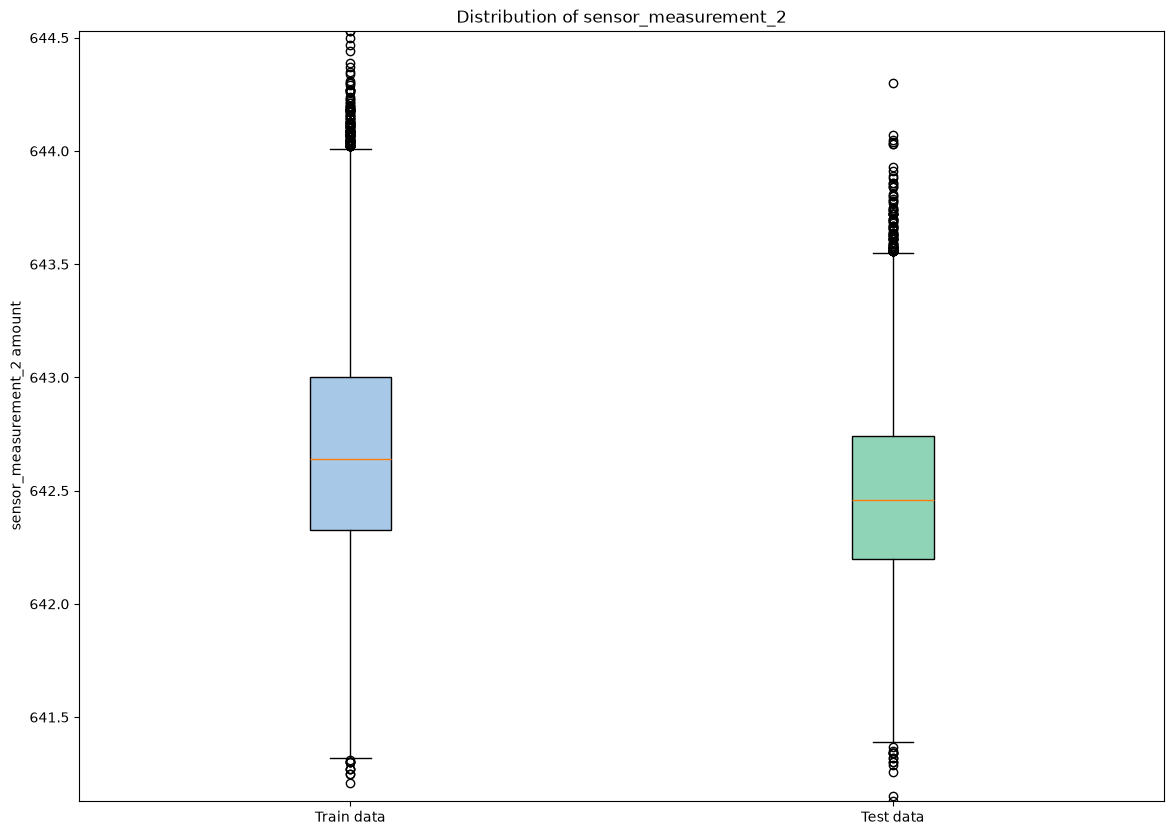

Train Dataframe
sensor_measurement_2
Q1: 642.3250000
Q3: 643.0000000
IQR: 0.6750000
Lower boundary: 641.3125000
Upper boundary: 644.0125000
Number of upper outliers : 117
Number of lower outliers : 11

Test Dataframe
sensor_measurement_2
Q1: 642.1975000
Q3: 642.7400000
IQR: 0.5425000
Lower boundary: 641.3837500
Upper boundary: 643.5537500
Number of upper outliers : 90
Number of lower outliers : 14



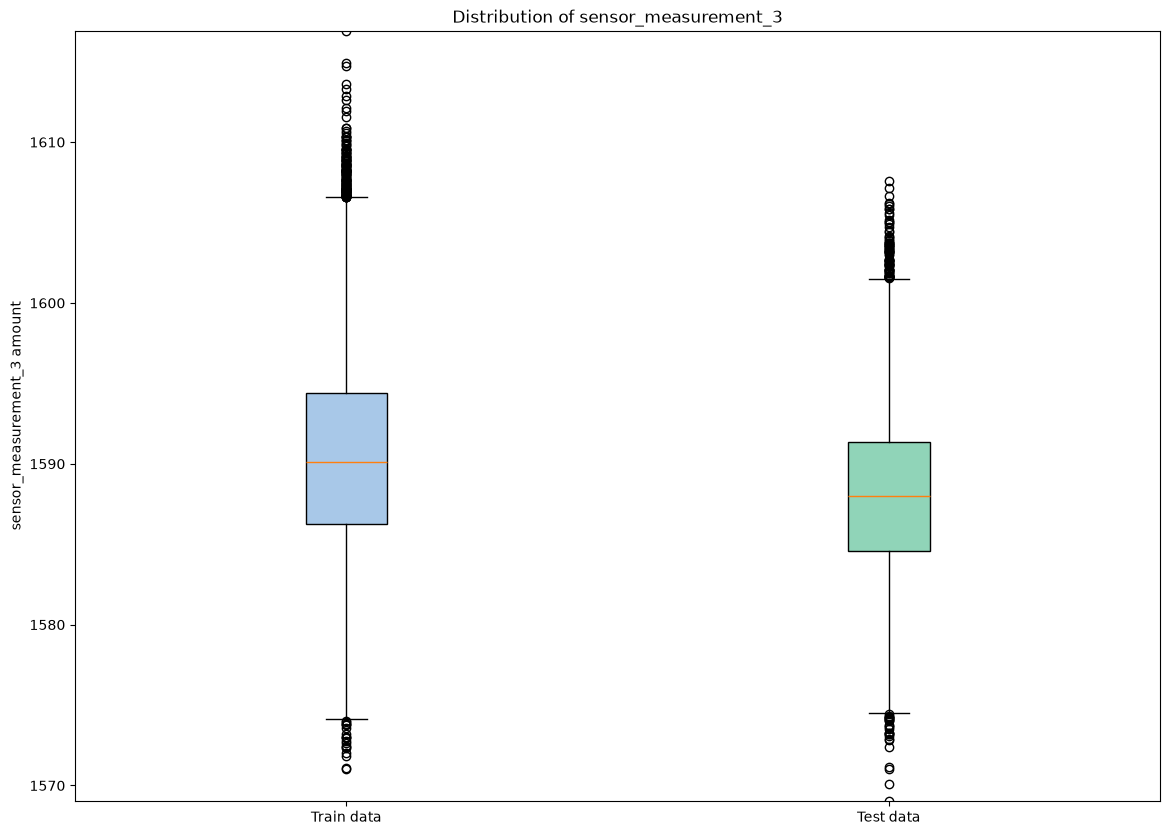

Train Dataframe
sensor_measurement_3
Q1: 1,586.2600000
Q3: 1,594.3800000
IQR: 8.1200000
Lower boundary: 1,574.0800000
Upper boundary: 1,606.5600000
Number of upper outliers : 146
Number of lower outliers : 19

Test Dataframe
sensor_measurement_3
Q1: 1,584.6000000
Q3: 1,591.3625000
IQR: 6.7625000
Lower boundary: 1,574.4562500
Upper boundary: 1,601.5062500
Number of upper outliers : 80
Number of lower outliers : 26



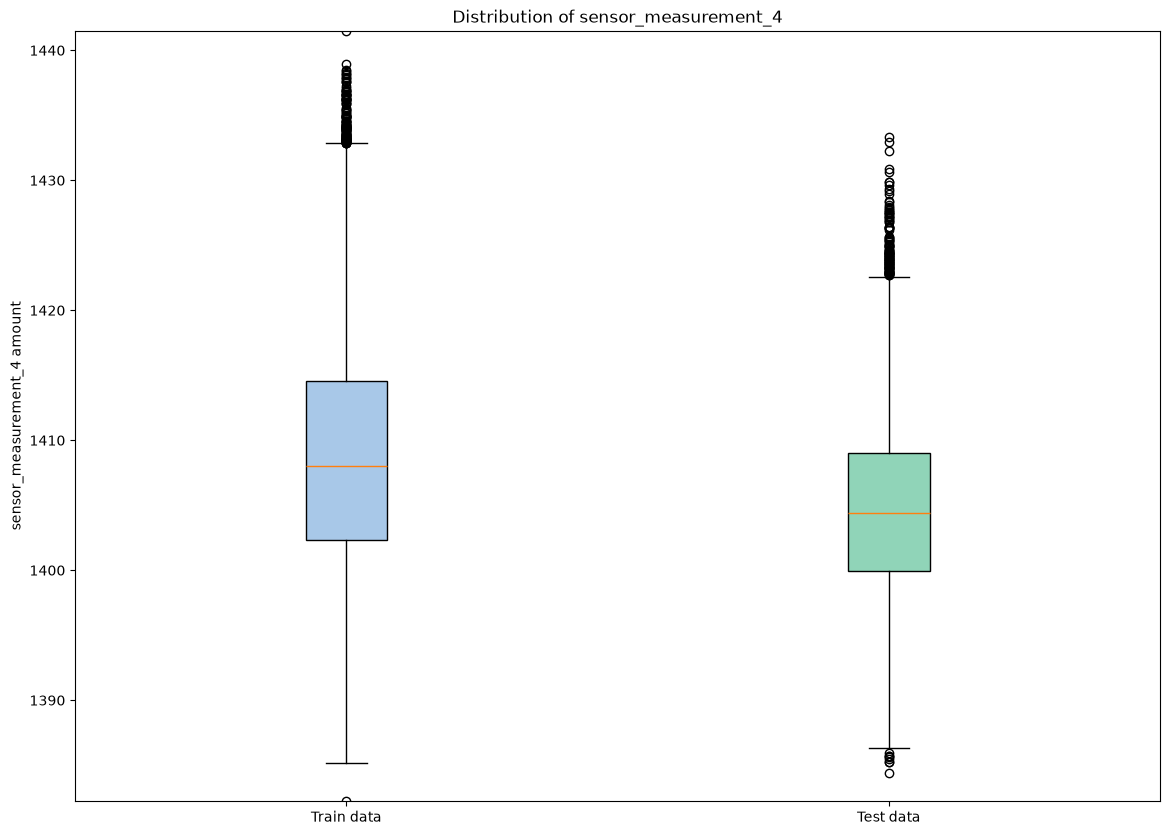

Train Dataframe
sensor_measurement_4
Q1: 1,402.3600000
Q3: 1,414.5550000
IQR: 12.1950000
Lower boundary: 1,384.0675000
Upper boundary: 1,432.8475000
Number of upper outliers : 119
Number of lower outliers : 1

Test Dataframe
sensor_measurement_4
Q1: 1,399.9500000
Q3: 1,409.0500000
IQR: 9.1000000
Lower boundary: 1,386.3000000
Upper boundary: 1,422.7000000
Number of upper outliers : 115
Number of lower outliers : 8



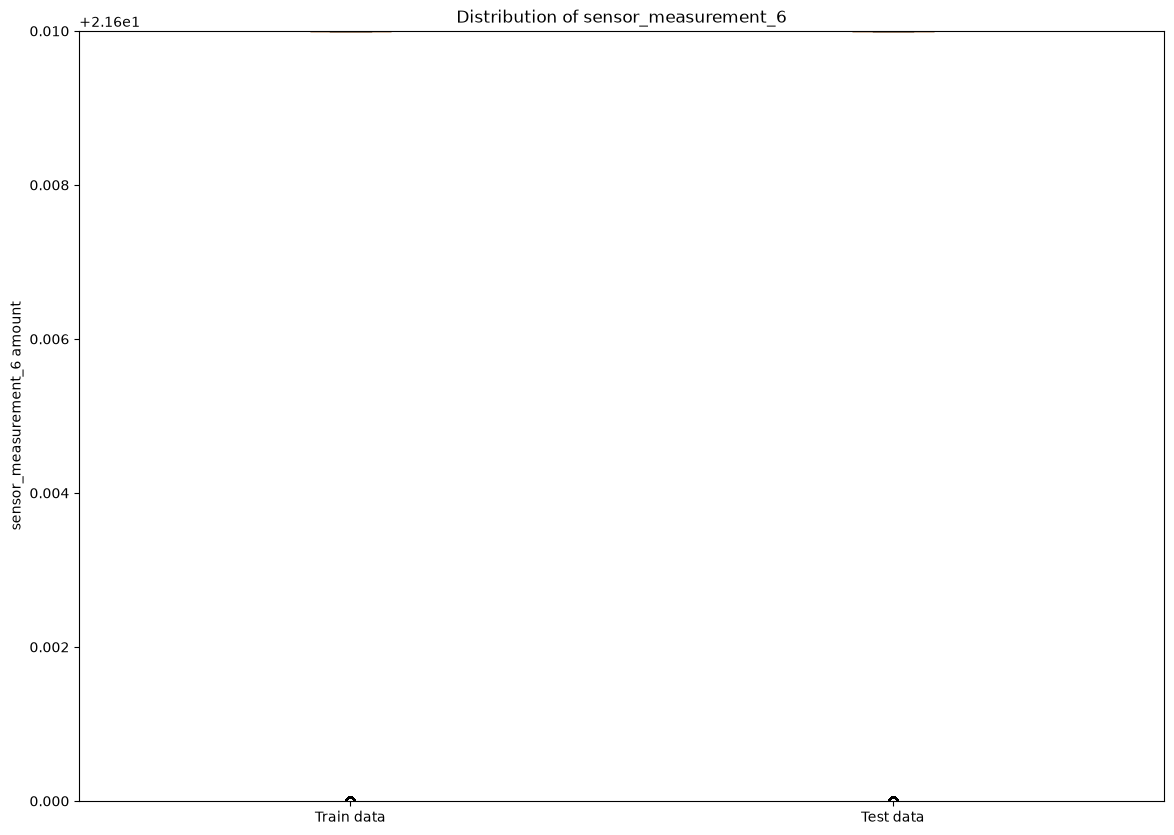

Train Dataframe
sensor_measurement_6
Q1: 21.6100000
Q3: 21.6100000
IQR: 0.0000000
Lower boundary: 21.6100000
Upper boundary: 21.6100000
Number of upper outliers : 0
Number of lower outliers : 406

Test Dataframe
sensor_measurement_6
Q1: 21.6100000
Q3: 21.6100000
IQR: 0.0000000
Lower boundary: 21.6100000
Upper boundary: 21.6100000
Number of upper outliers : 0
Number of lower outliers : 392



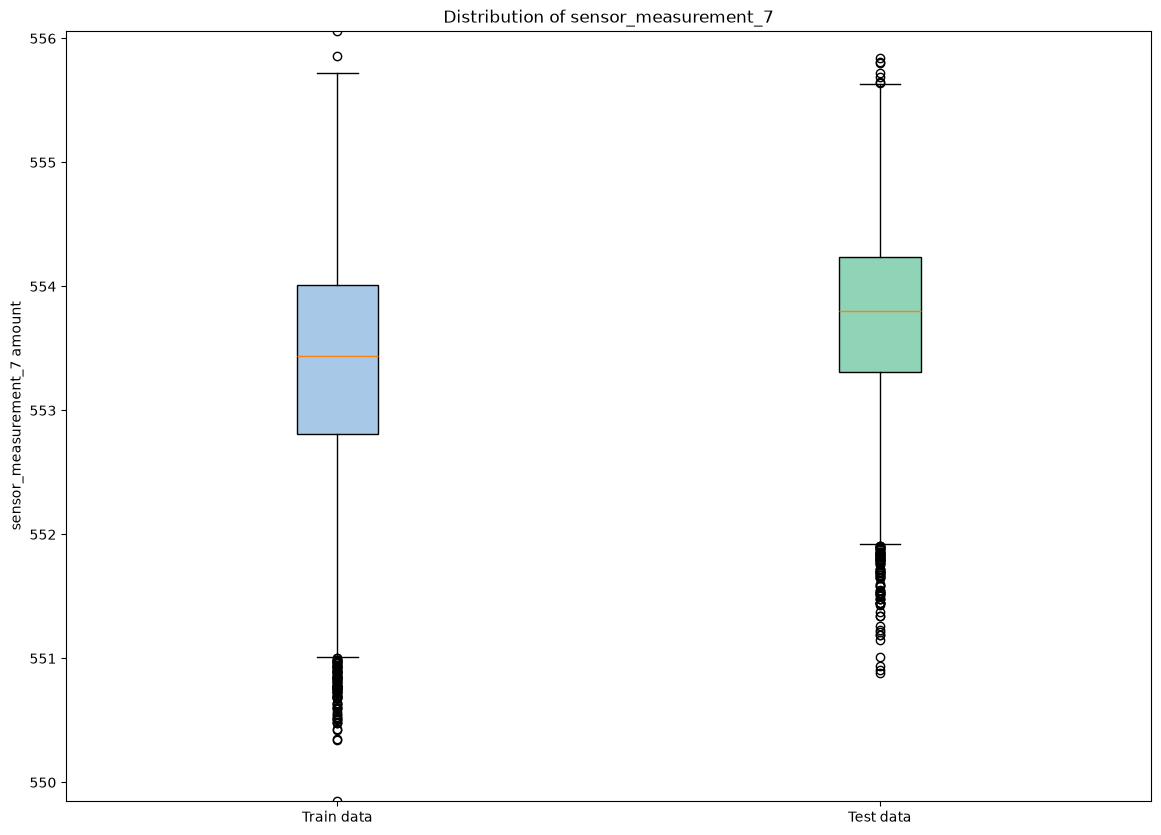

Train Dataframe
sensor_measurement_7
Q1: 552.8100000
Q3: 554.0100000
IQR: 1.2000000
Lower boundary: 551.0100000
Upper boundary: 555.8100000
Number of upper outliers : 2
Number of lower outliers : 108

Test Dataframe
sensor_measurement_7
Q1: 553.3100000
Q3: 554.2400000
IQR: 0.9300000
Lower boundary: 551.9150000
Upper boundary: 555.6350000
Number of upper outliers : 7
Number of lower outliers : 96



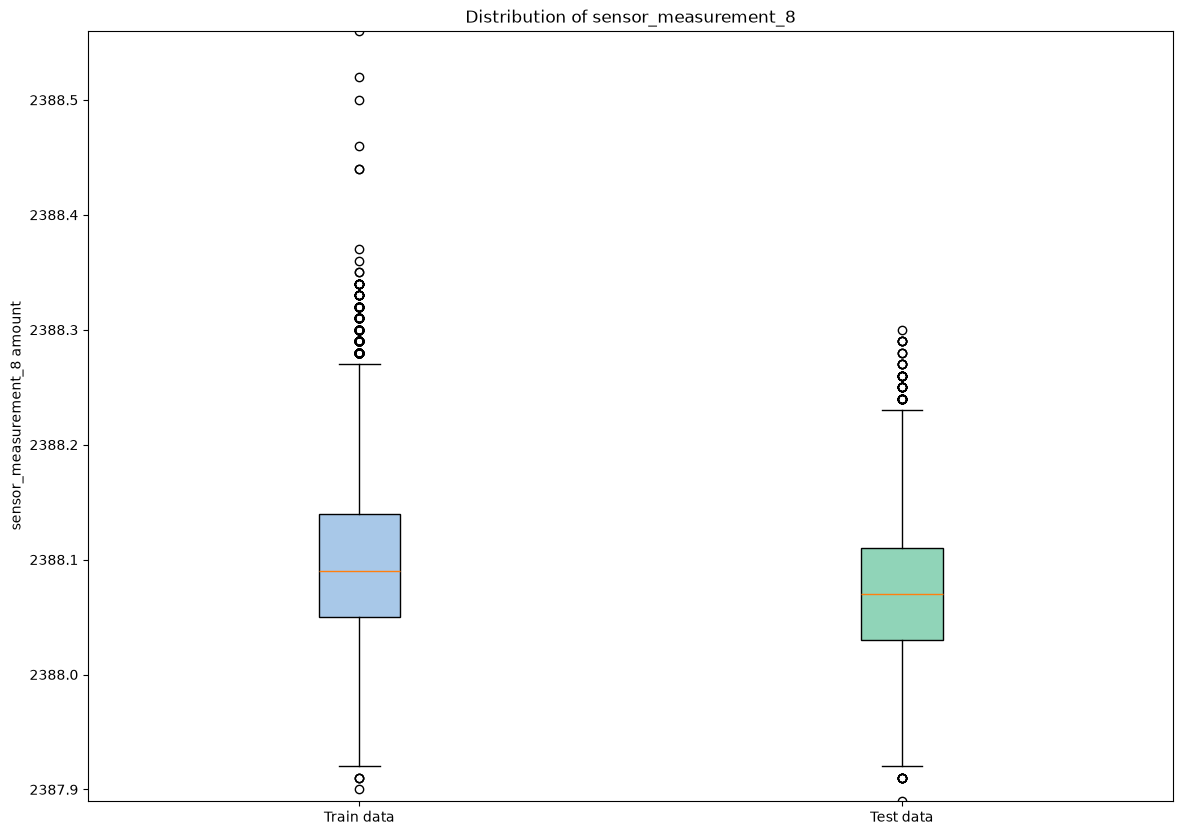

Train Dataframe
sensor_measurement_8
Q1: 2,388.0500000
Q3: 2,388.1400000
IQR: 0.0900000
Lower boundary: 2,387.9150000
Upper boundary: 2,388.2750000
Number of upper outliers : 316
Number of lower outliers : 4

Test Dataframe
sensor_measurement_8
Q1: 2,388.0300000
Q3: 2,388.1100000
IQR: 0.0800000
Lower boundary: 2,387.9100000
Upper boundary: 2,388.2300000
Number of upper outliers : 60
Number of lower outliers : 9



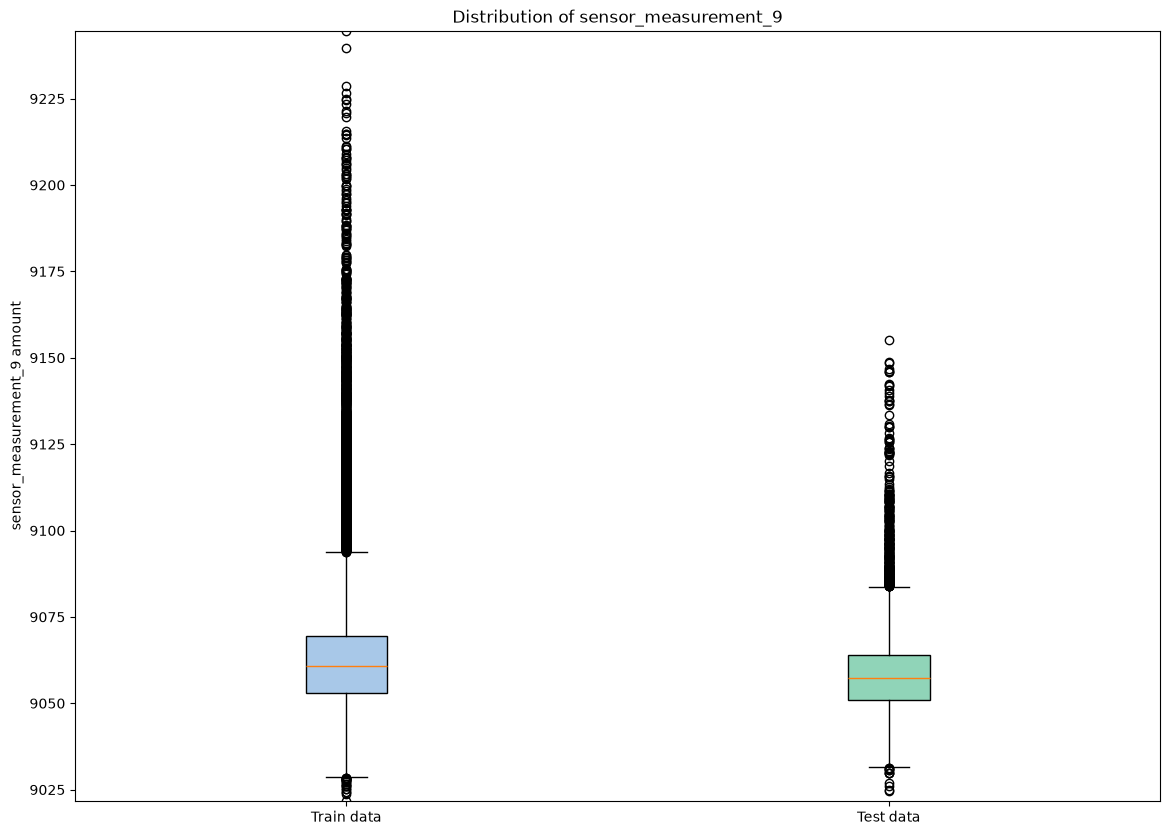

Train Dataframe
sensor_measurement_9
Q1: 9,053.1000000
Q3: 9,069.4200000
IQR: 16.3200000
Lower boundary: 9,028.6200000
Upper boundary: 9,093.9000000
Number of upper outliers : 1663
Number of lower outliers : 23

Test Dataframe
sensor_measurement_9
Q1: 9,051.0200000
Q3: 9,064.1100000
IQR: 13.0900000
Lower boundary: 9,031.3850000
Upper boundary: 9,083.7450000
Number of upper outliers : 323
Number of lower outliers : 12



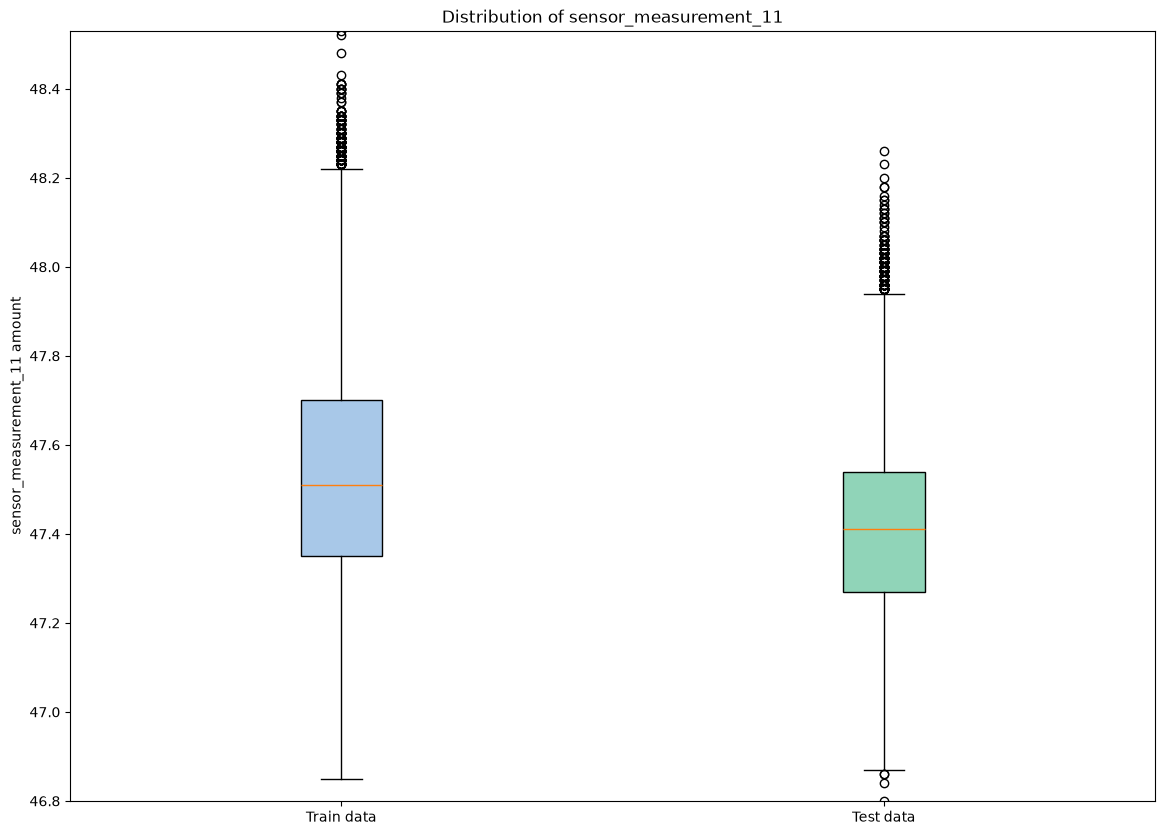

Train Dataframe
sensor_measurement_11
Q1: 47.3500000
Q3: 47.7000000
IQR: 0.3500000
Lower boundary: 46.8250000
Upper boundary: 48.2250000
Number of upper outliers : 167
Number of lower outliers : 0

Test Dataframe
sensor_measurement_11
Q1: 47.2700000
Q3: 47.5400000
IQR: 0.2700000
Lower boundary: 46.8650000
Upper boundary: 47.9450000
Number of upper outliers : 136
Number of lower outliers : 4



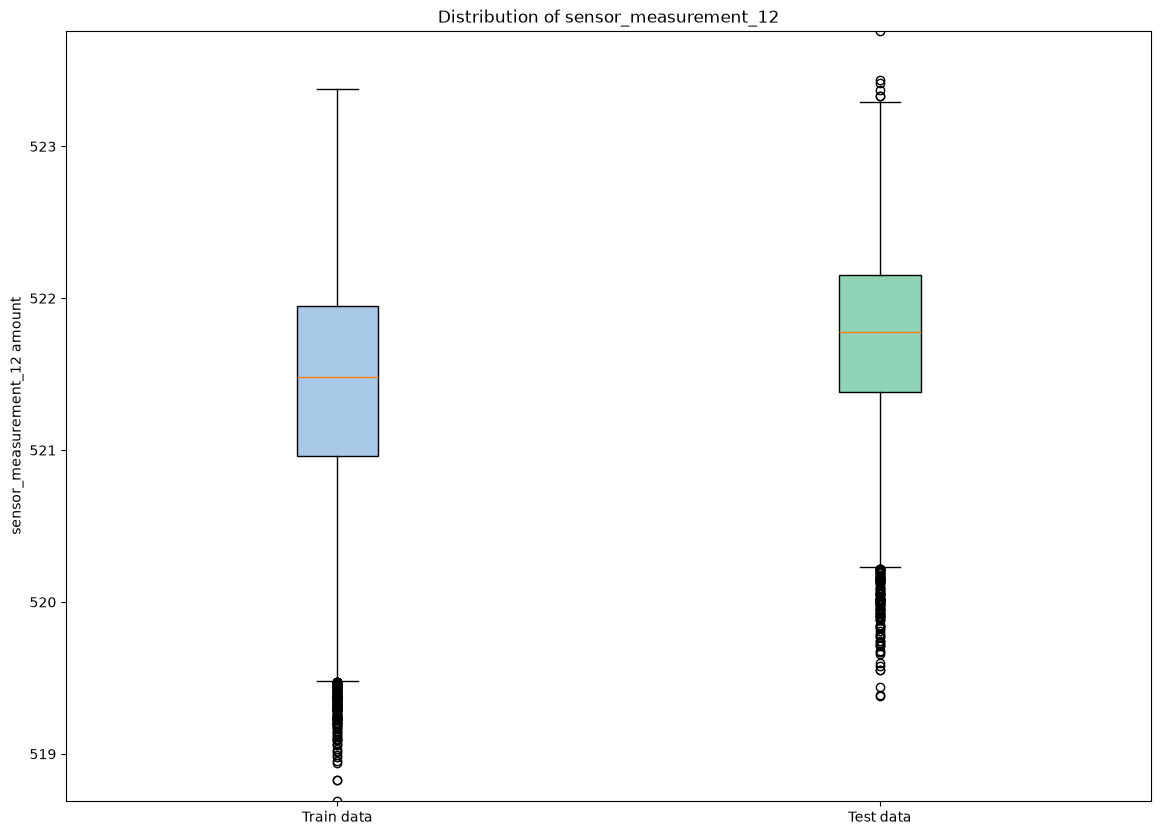

Train Dataframe
sensor_measurement_12
Q1: 520.9600000
Q3: 521.9500000
IQR: 0.9900000
Lower boundary: 519.4750000
Upper boundary: 523.4350000
Number of upper outliers : 0
Number of lower outliers : 146

Test Dataframe
sensor_measurement_12
Q1: 521.3800000
Q3: 522.1500000
IQR: 0.7700000
Lower boundary: 520.2250000
Upper boundary: 523.3050000
Number of upper outliers : 6
Number of lower outliers : 114



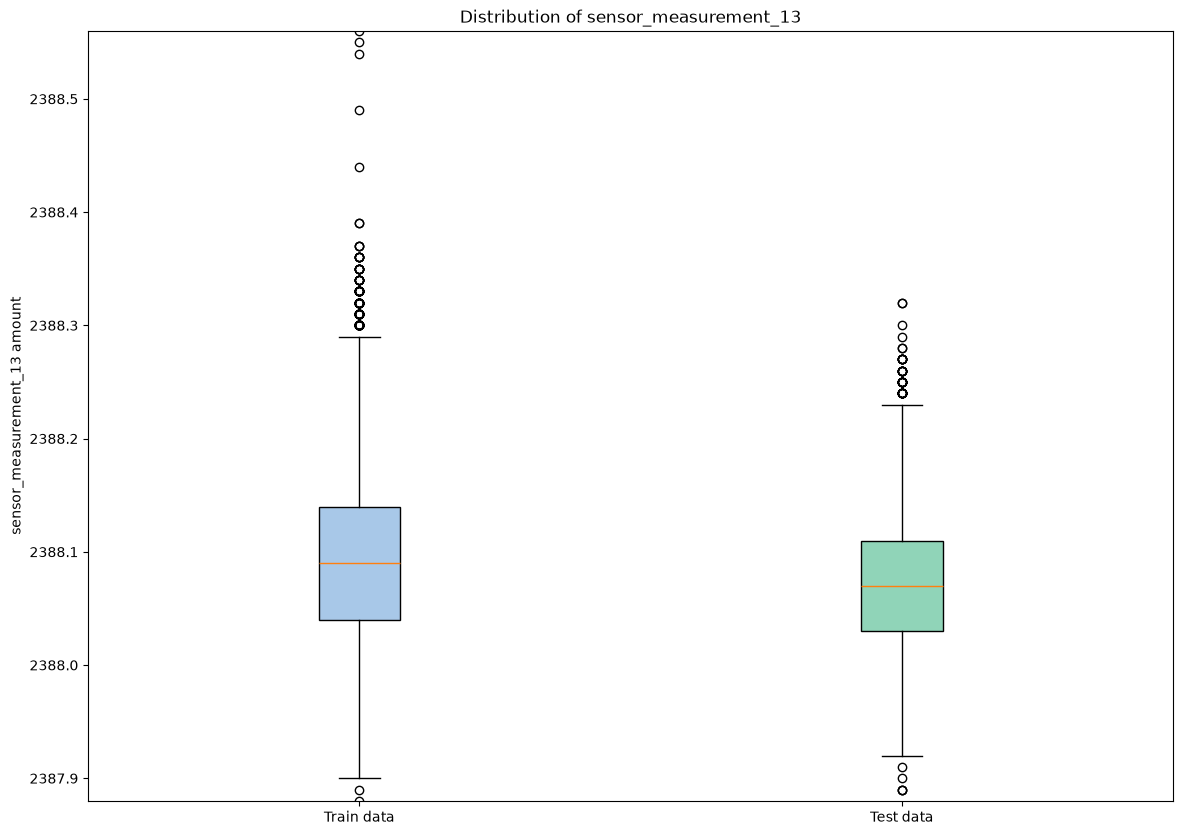

Train Dataframe
sensor_measurement_13
Q1: 2,388.0400000
Q3: 2,388.1400000
IQR: 0.1000000
Lower boundary: 2,387.8900000
Upper boundary: 2,388.2900000
Number of upper outliers : 159
Number of lower outliers : 2

Test Dataframe
sensor_measurement_13
Q1: 2,388.0300000
Q3: 2,388.1100000
IQR: 0.0800000
Lower boundary: 2,387.9100000
Upper boundary: 2,388.2300000
Number of upper outliers : 50
Number of lower outliers : 5



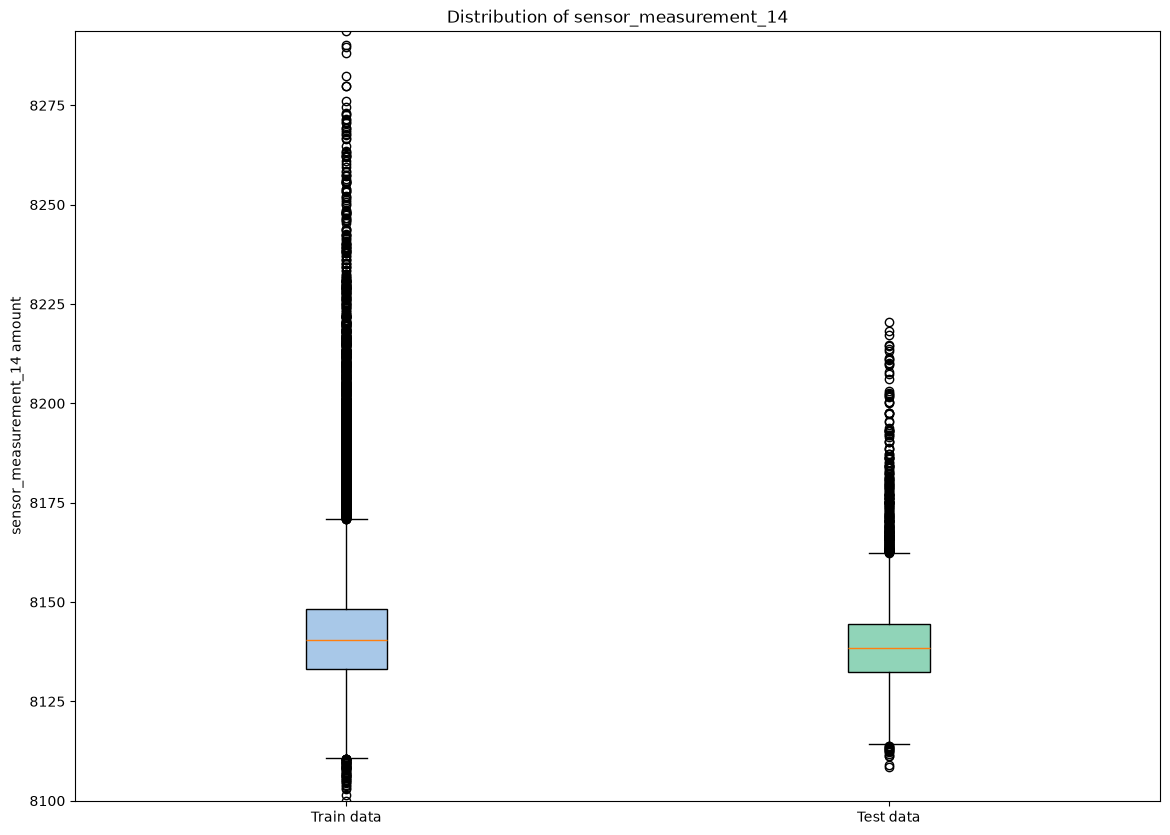

Train Dataframe
sensor_measurement_14
Q1: 8,133.2450000
Q3: 8,148.3100000
IQR: 15.0650000
Lower boundary: 8,110.6475000
Upper boundary: 8,170.9075000
Number of upper outliers : 1483
Number of lower outliers : 60

Test Dataframe
sensor_measurement_14
Q1: 8,132.3100000
Q3: 8,144.3600000
IQR: 12.0500000
Lower boundary: 8,114.2350000
Upper boundary: 8,162.4350000
Number of upper outliers : 267
Number of lower outliers : 16



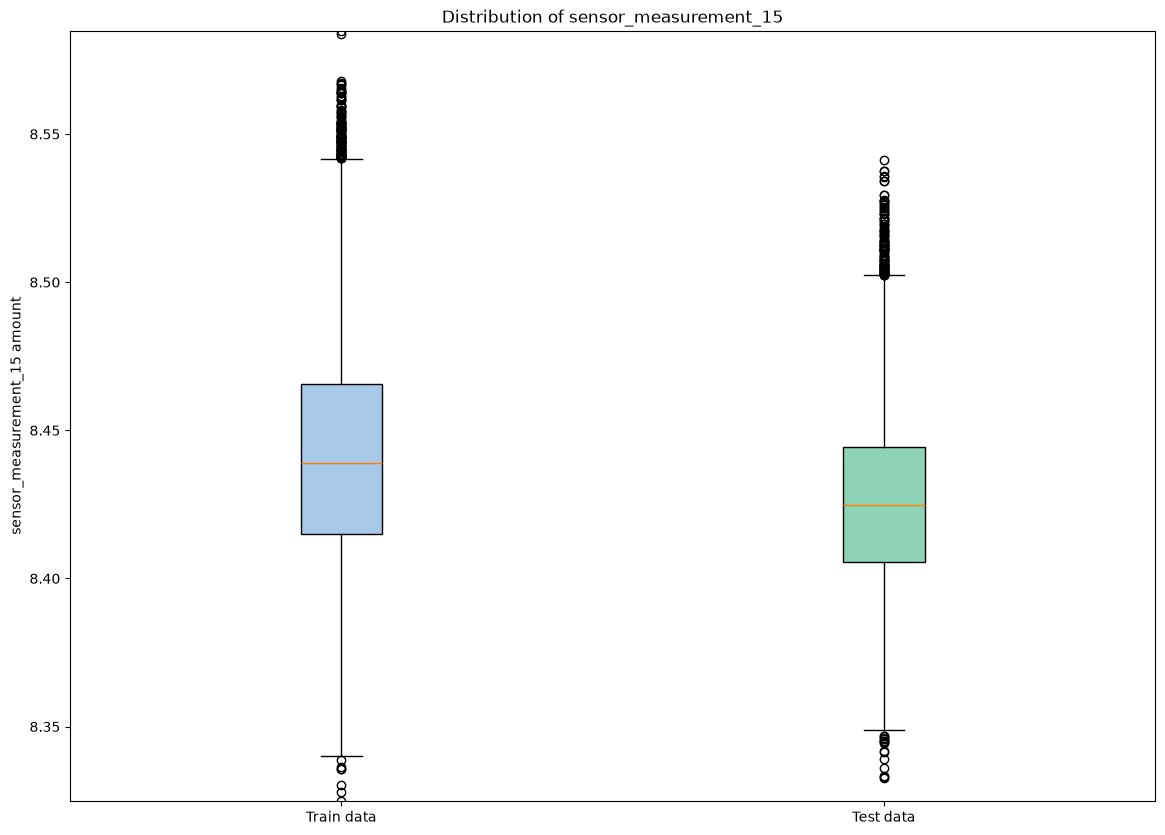

Train Dataframe
sensor_measurement_15
Q1: 8.4149000
Q3: 8.4656000
IQR: 0.0507000
Lower boundary: 8.3388500
Upper boundary: 8.5416500
Number of upper outliers : 113
Number of lower outliers : 7

Test Dataframe
sensor_measurement_15
Q1: 8.4056000
Q3: 8.4443000
IQR: 0.0387000
Lower boundary: 8.3475500
Upper boundary: 8.5023500
Number of upper outliers : 102
Number of lower outliers : 15



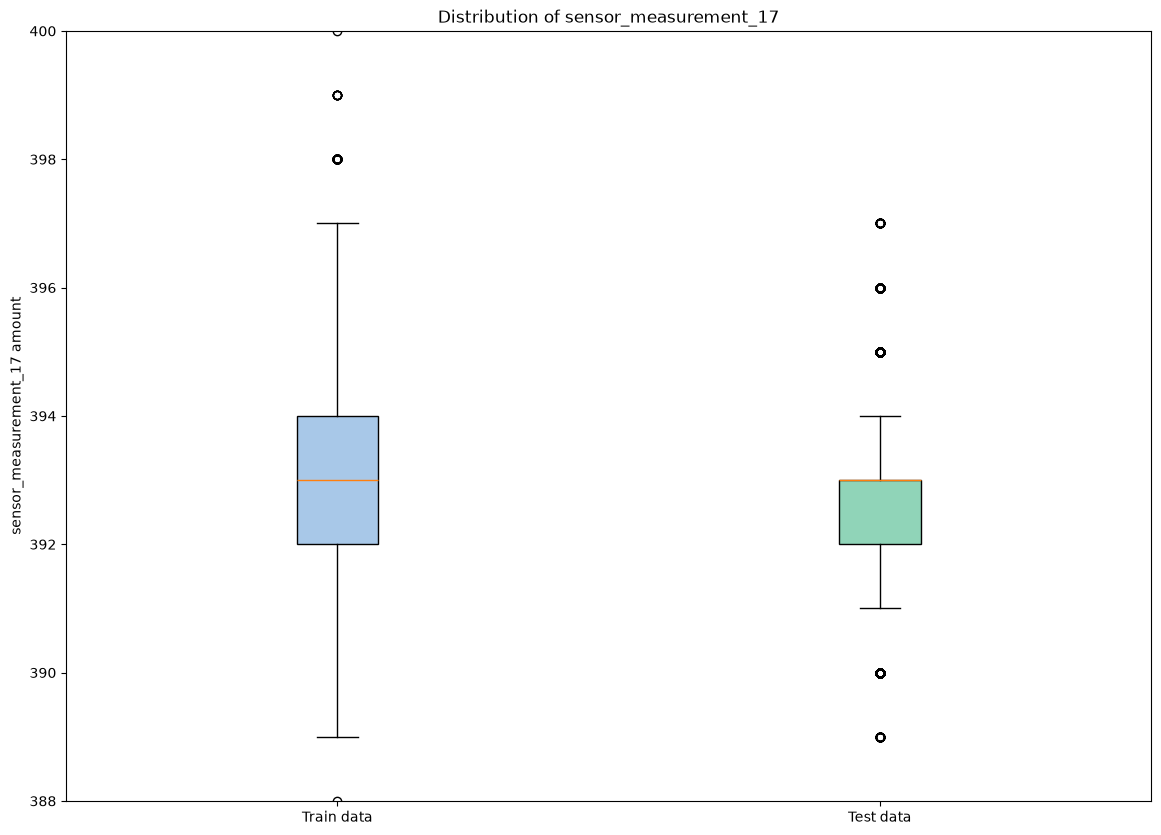

Train Dataframe
sensor_measurement_17
Q1: 392.0000000
Q3: 394.0000000
IQR: 2.0000000
Lower boundary: 389.0000000
Upper boundary: 397.0000000
Number of upper outliers : 80
Number of lower outliers : 1

Test Dataframe
sensor_measurement_17
Q1: 392.0000000
Q3: 393.0000000
IQR: 1.0000000
Lower boundary: 390.5000000
Upper boundary: 394.5000000
Number of upper outliers : 791
Number of lower outliers : 448



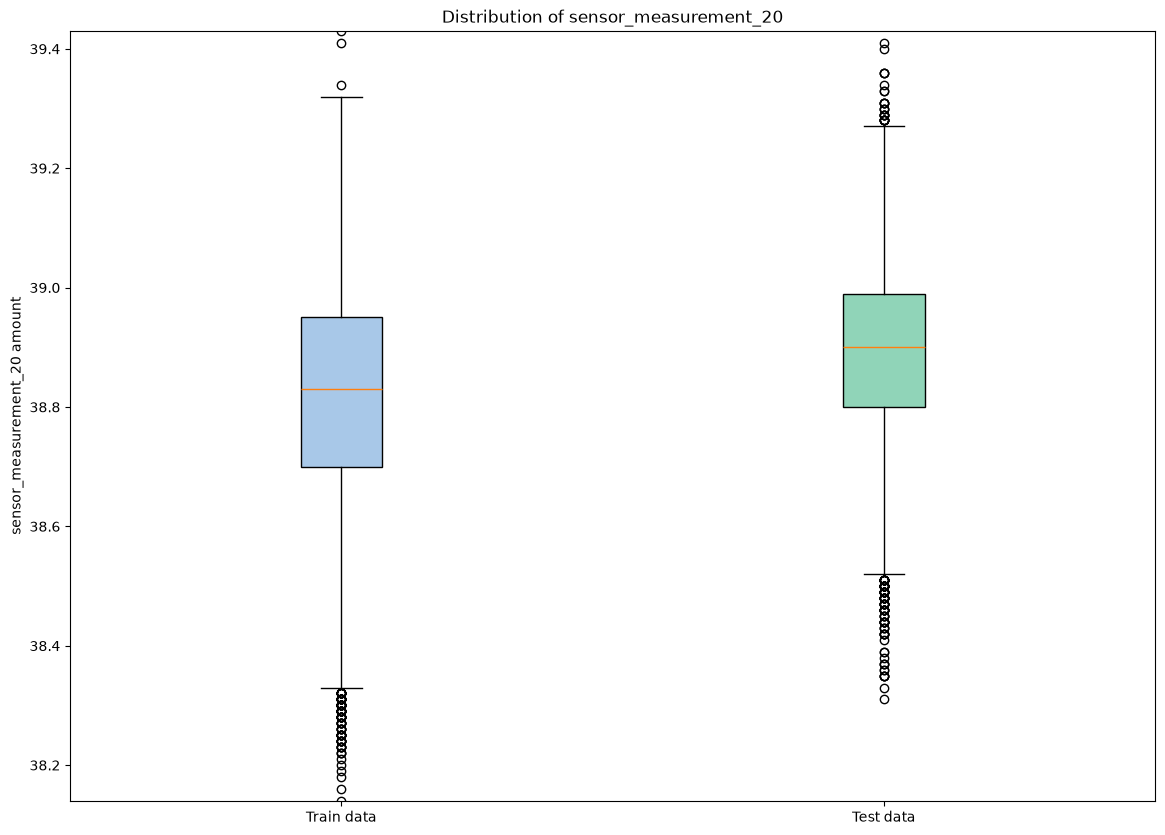

Train Dataframe
sensor_measurement_20
Q1: 38.7000000
Q3: 38.9500000
IQR: 0.2500000
Lower boundary: 38.3250000
Upper boundary: 39.3250000
Number of upper outliers : 3
Number of lower outliers : 114

Test Dataframe
sensor_measurement_20
Q1: 38.8000000
Q3: 38.9900000
IQR: 0.1900000
Lower boundary: 38.5150000
Upper boundary: 39.2750000
Number of upper outliers : 27
Number of lower outliers : 102



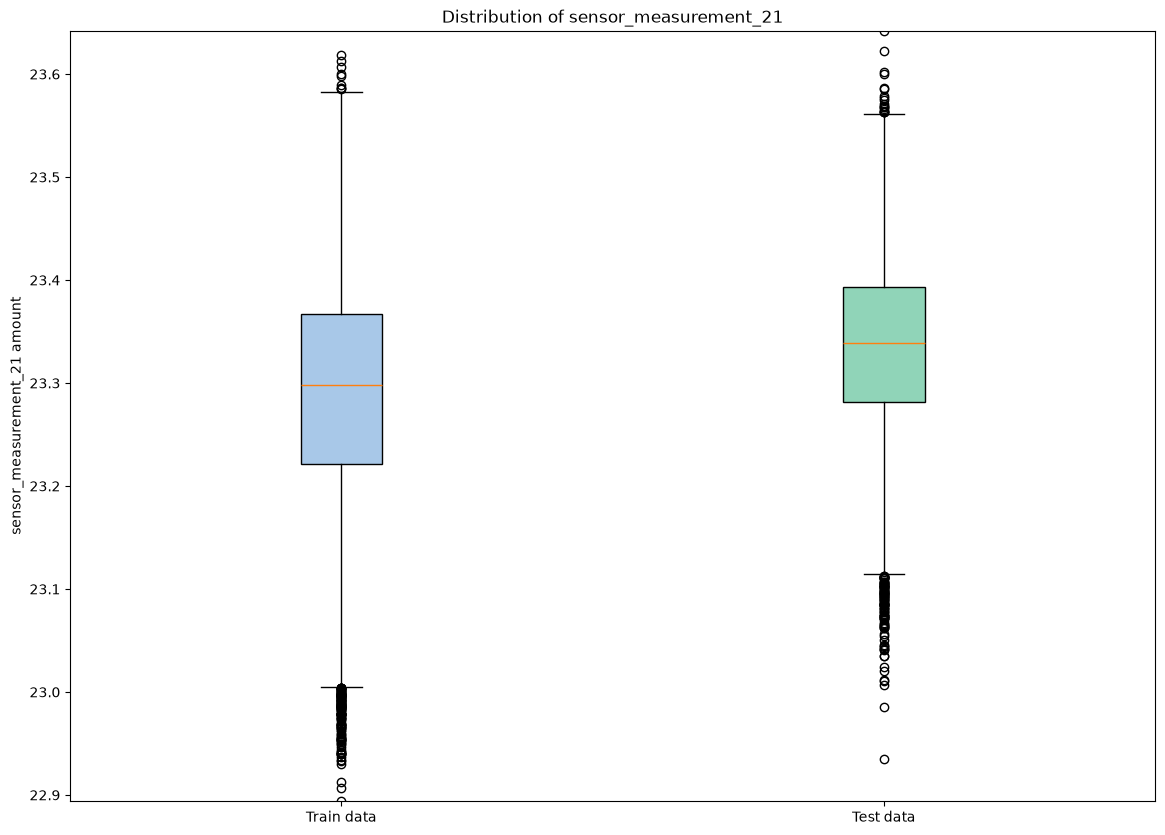

Train Dataframe
sensor_measurement_21
Q1: 23.2218000
Q3: 23.3668000
IQR: 0.1450000
Lower boundary: 23.0043000
Upper boundary: 23.5843000
Number of upper outliers : 9
Number of lower outliers : 127

Test Dataframe
sensor_measurement_21
Q1: 23.2816000
Q3: 23.3936000
IQR: 0.1120000
Lower boundary: 23.1136000
Upper boundary: 23.5616000
Number of upper outliers : 18
Number of lower outliers : 103



In [31]:
if shared_columns:
    for column in shared_columns:    
        plt.figure(figsize=(14,10))
        bp = plt.boxplot([train_df_minio[column],test_df_minio[column]],
                         tick_labels=["Train data","Test data"],
                         patch_artist=True,
                         notch=False)
        colors = ['#a8c8e8', '#90d4b8', '#f4b8b8']
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)
        plt.title(f"Distribution of {column}")
        plt.ylabel(f"{column} amount")
        plt.ylim(min(float(train_df_minio[column].min()),float(test_df_minio[column].min())),max(float(train_df_minio[column].max()),float(test_df_minio[column].max())))
        plt.show()
        print("Train Dataframe")
        print(column)
        Q1 = train_df_minio[column].quantile(0.25)
        Q3 = train_df_minio[column].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        print(f'Q1: {Q1:,.7f}')
        print(f'Q3: {Q3:,.7f}')
        print(f'IQR: {IQR:,.7f}')
        print(f'Lower boundary: {lower:,.7f}')
        print(f'Upper boundary: {upper:,.7f}')

        upper_outliers = train_df_minio[train_df_minio[column] > upper]
        lower_outliers = train_df_minio[train_df_minio[column] < lower]
        print(f'Number of upper outliers : {len(upper_outliers)}')
        print(f'Number of lower outliers : {len(lower_outliers)}\n')

        print("Test Dataframe")
        print(column)
        Q1 = test_df_minio[column].quantile(0.25)
        Q3 = test_df_minio[column].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        print(f'Q1: {Q1:,.7f}')
        print(f'Q3: {Q3:,.7f}')
        print(f'IQR: {IQR:,.7f}')
        print(f'Lower boundary: {lower:,.7f}')
        print(f'Upper boundary: {upper:,.7f}')

        upper_outliers = test_df_minio[test_df_minio[column] > upper]
        lower_outliers = test_df_minio[test_df_minio[column] < lower]
        print(f'Number of upper outliers : {len(upper_outliers)}')
        print(f'Number of lower outliers : {len(lower_outliers)}\n')

In [68]:
rul_df_minio.head()

,unit_number,remaining_useful_life
0,1,112
1,2,98
2,3,69
3,4,82
4,5,91


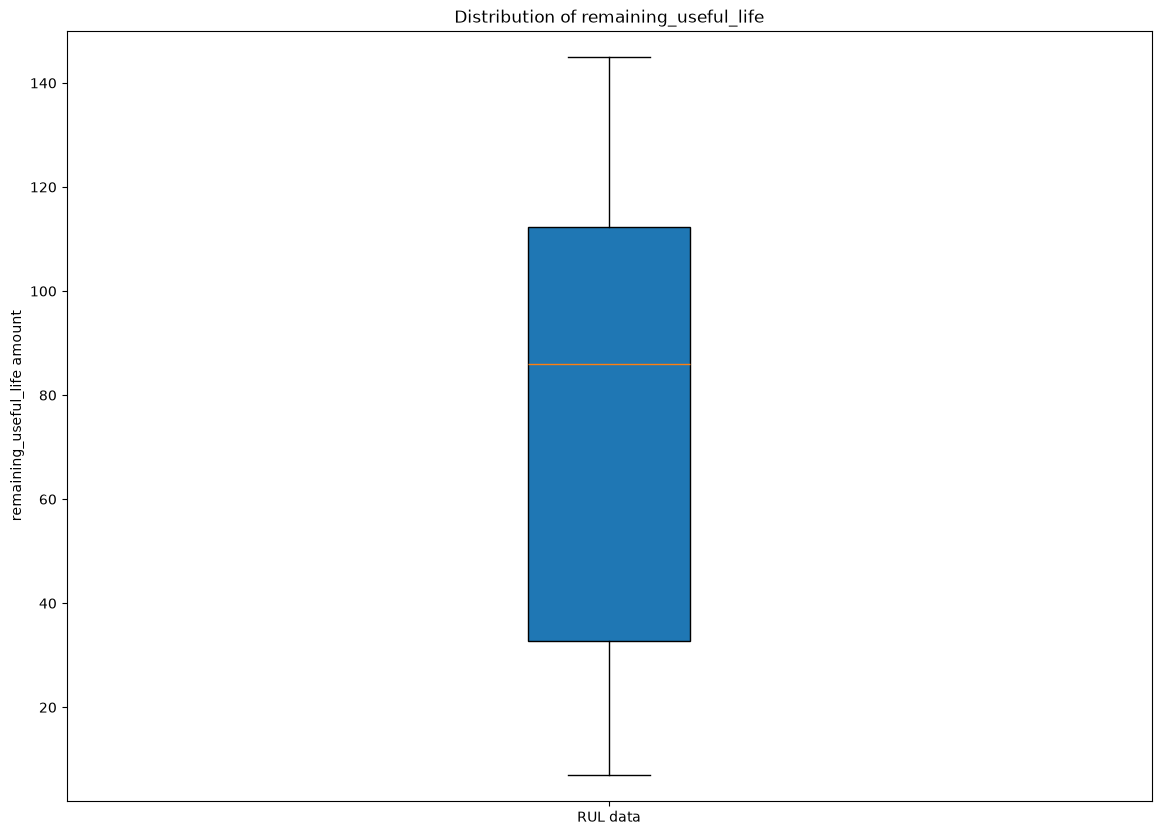

RUL Dataframe
remaining_useful_life
Q1: 32.7500000
Q3: 112.2500000
IQR: 79.5000000
Lower boundary: -86.5000000
Upper boundary: 231.5000000
Number of upper outliers : 0
Number of lower outliers : 0



In [72]:
plt.figure(figsize=(14,10))
plt.boxplot([rul_df_minio["remaining_useful_life"]],
                    tick_labels=["RUL data"],
                    patch_artist=True,
                    notch=False)
plt.title(f"Distribution of remaining_useful_life")
plt.ylabel(f"remaining_useful_life amount")
plt.ylim(float(rul_df_minio["remaining_useful_life"].min())-5, float(rul_df_minio["remaining_useful_life"].max())+5)
plt.show()
print("RUL Dataframe")
print("remaining_useful_life")
Q1 = rul_df_minio["remaining_useful_life"].quantile(0.25)
Q3 = rul_df_minio["remaining_useful_life"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f'Q1: {Q1:,.7f}')
print(f'Q3: {Q3:,.7f}')
print(f'IQR: {IQR:,.7f}')
print(f'Lower boundary: {lower:,.7f}')
print(f'Upper boundary: {upper:,.7f}')

upper_outliers = rul_df_minio[rul_df_minio["remaining_useful_life"] > upper]
lower_outliers = rul_df_minio[rul_df_minio["remaining_useful_life"] < lower]
print(f'Number of upper outliers : {len(upper_outliers)}')
print(f'Number of lower outliers : {len(lower_outliers)}\n')

In [32]:
if train_unique_columns:    
    for column in train_unique_columns:    
        plt.figure(figsize=(14,10))
        plt.boxplot(train_df_minio[column],patch_artist=True,notch=False)
        plt.title(f"Distribution of {column}")
        plt.ylabel(f"{column} amount")
        plt.ylim(train_df_minio[column].min(),train_df_minio[column].max())
        plt.show()
        print(column)
        Q1 = train_df_minio[column].quantile(0.25)
        Q3 = train_df_minio[column].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        print(f'Q1: {Q1:,.7f}')
        print(f'Q3: {Q3:,.7f}')
        print(f'IQR: {IQR:,.7f}')
        print(f'Lower boundary: {lower:,.7f}')
        print(f'Upper boundary: {upper:,.7f}')

        upper_outliers = train_df_minio[train_df_minio[column] > upper]
        lower_outliers = train_df_minio[train_df_minio[column] < lower]
        print(f'Number of upper outliers : {len(upper_outliers)}')
        print(f'Number of lower outliers : {len(lower_outliers)}\n')

In [33]:
if test_unique_columns:
    for column in test_unique_columns:    
            plt.figure(figsize=(14,10))
            plt.boxplot(test_df_minio[column],patch_artist=True,notch=False)
            plt.title(f"Distribution of {column}")
            plt.ylabel(f"{column} amount")
            plt.ylim(test_df_minio[column].min(),test_df_minio[column].max())
            plt.show()
            print(column)
            Q1 = test_df_minio[column].quantile(0.25)
            Q3 = test_df_minio[column].quantile(0.75)
            IQR = Q3 - Q1
    
            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR
    
            print(f'Q1: {Q1:,.7f}')
            print(f'Q3: {Q3:,.7f}')
            print(f'IQR: {IQR:,.7f}')
            print(f'Lower boundary: {lower:,.7f}')
            print(f'Upper boundary: {upper:,.7f}')
    
            upper_outliers = test_df_minio[test_df_minio[column] > upper]
            lower_outliers = test_df_minio[test_df_minio[column] < lower]
            print(f'Number of upper outliers : {len(upper_outliers)}')
            print(f'Number of lower outliers : {len(lower_outliers)}\n')

In [34]:
import seaborn as sns

In [35]:
train_select_engines = [train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[0],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((0.25*len(train_engine_lifetime))-1)],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((0.5*len(train_engine_lifetime))-1)],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((0.75*len(train_engine_lifetime))-1)],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((1*len(train_engine_lifetime))-1)]]

In [36]:
train_columns

['sensor_measurement_2',
 'sensor_measurement_3',
 'sensor_measurement_4',
 'sensor_measurement_6',
 'sensor_measurement_7',
 'sensor_measurement_8',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_13',
 'sensor_measurement_14',
 'sensor_measurement_15',
 'sensor_measurement_17',
 'sensor_measurement_20',
 'sensor_measurement_21']

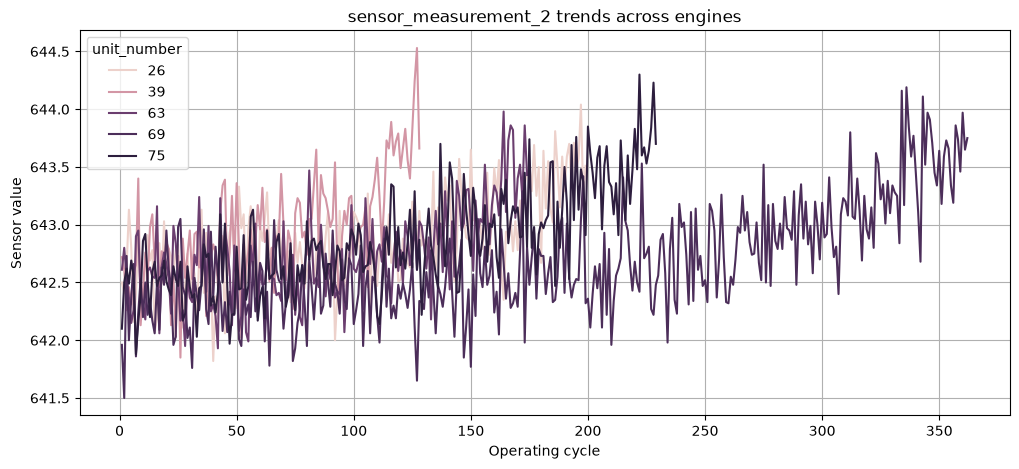

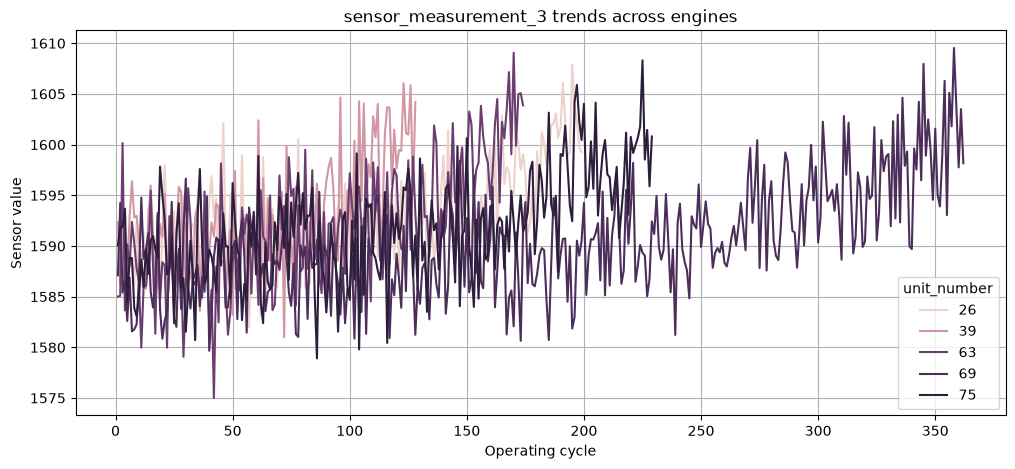

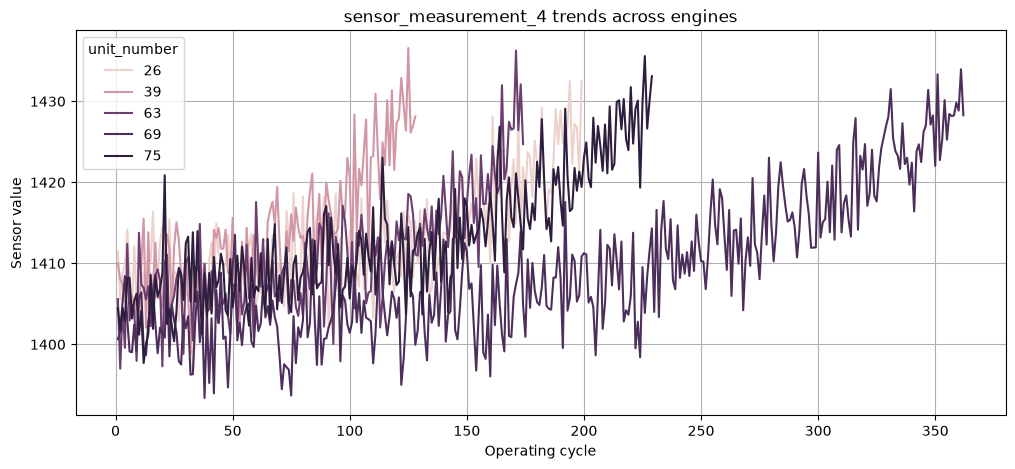

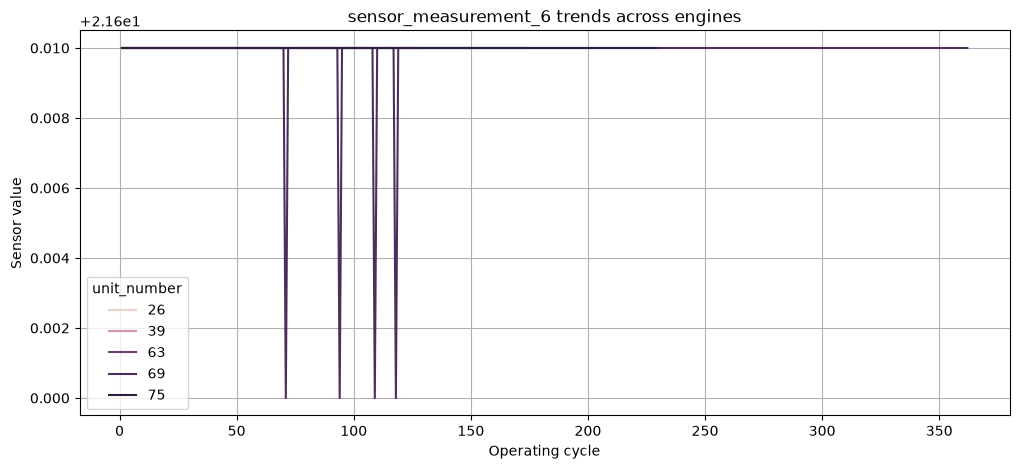

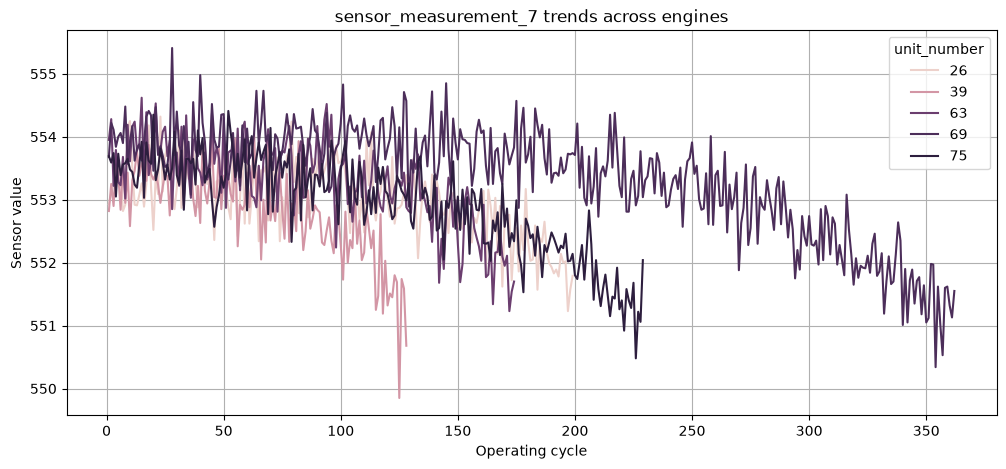

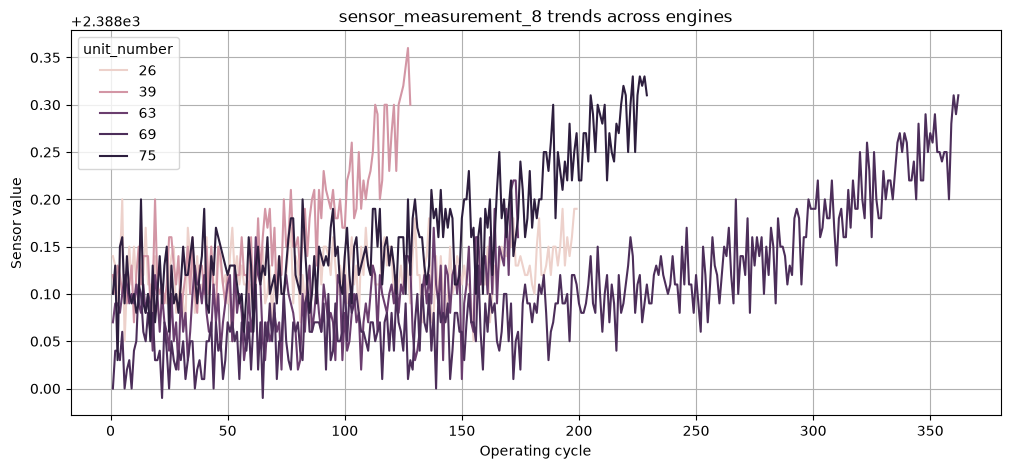

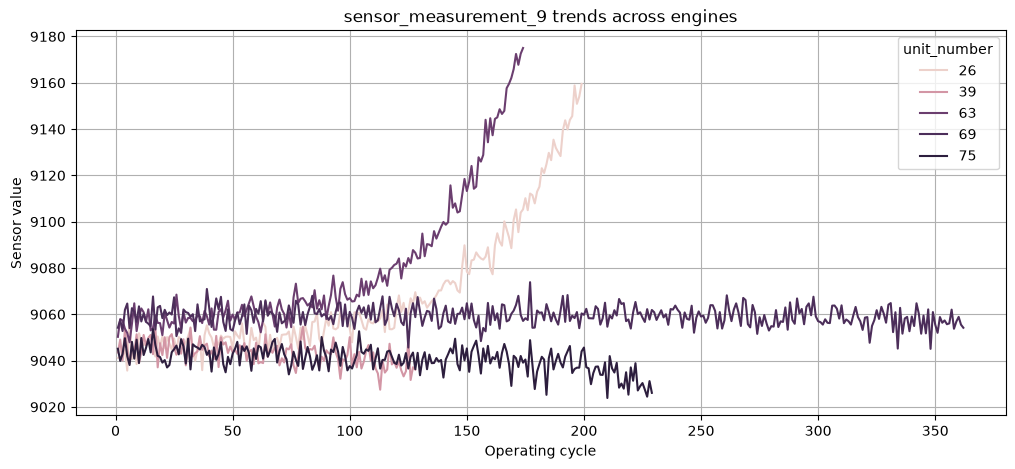

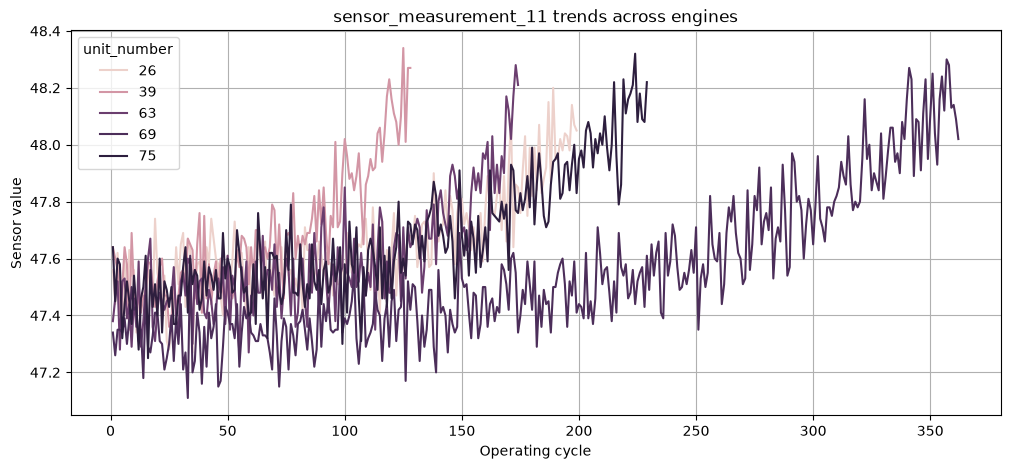

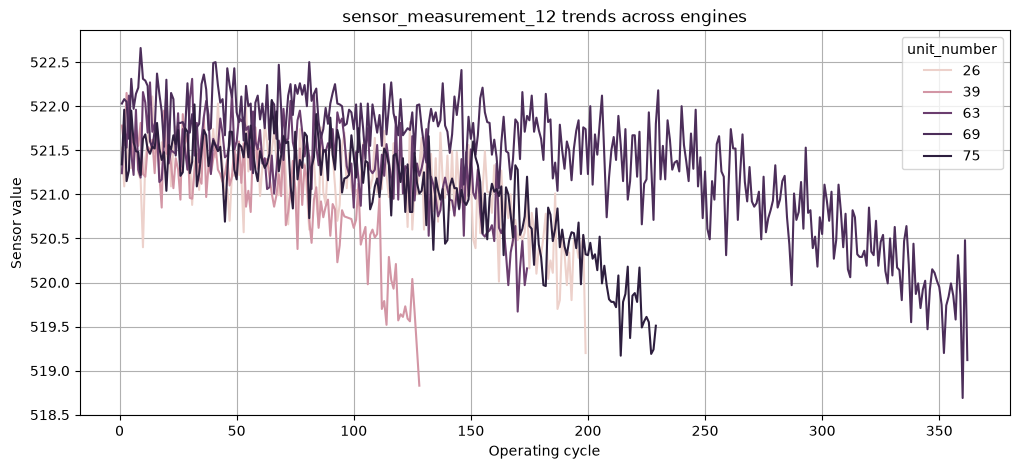

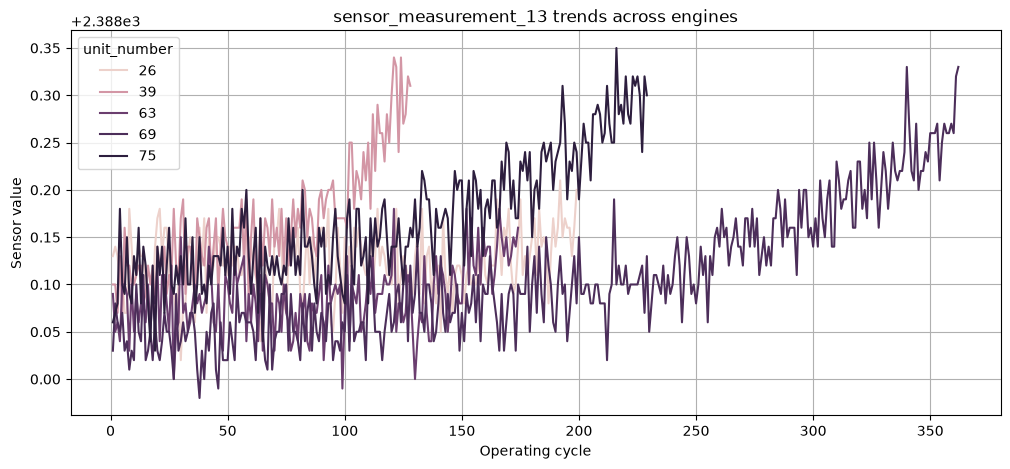

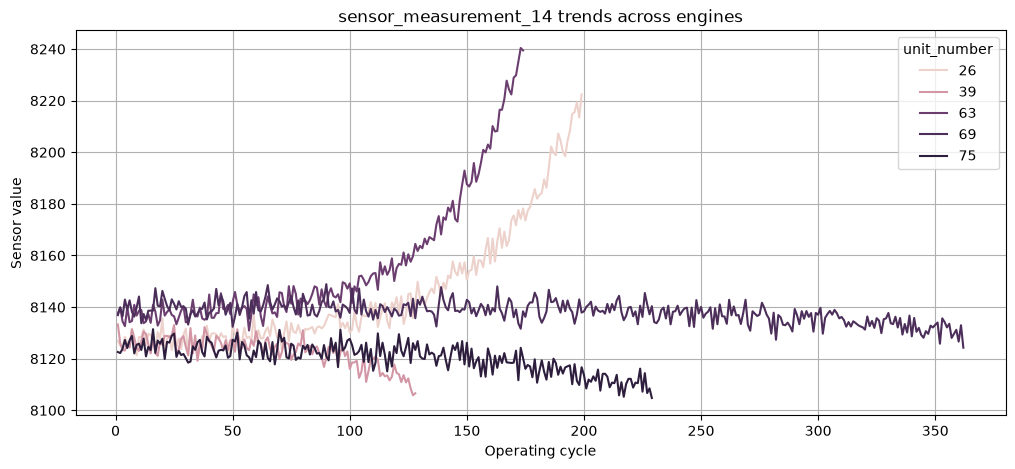

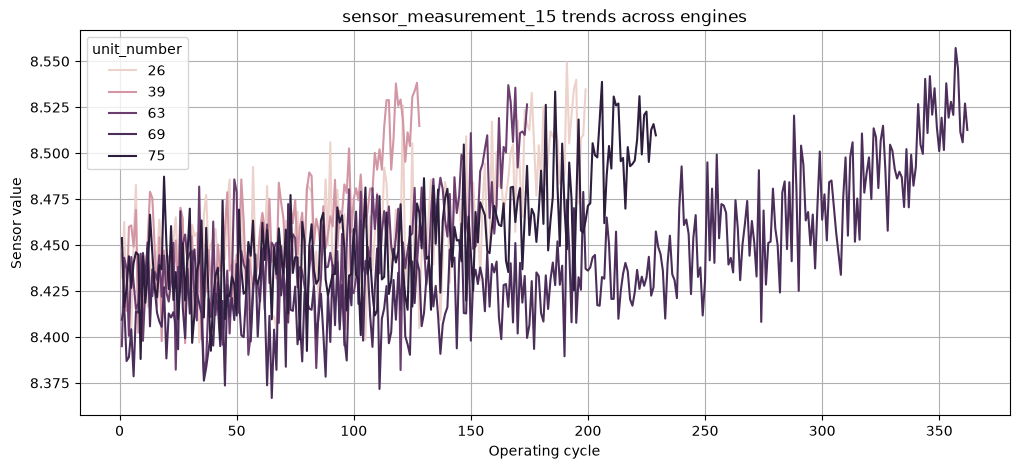

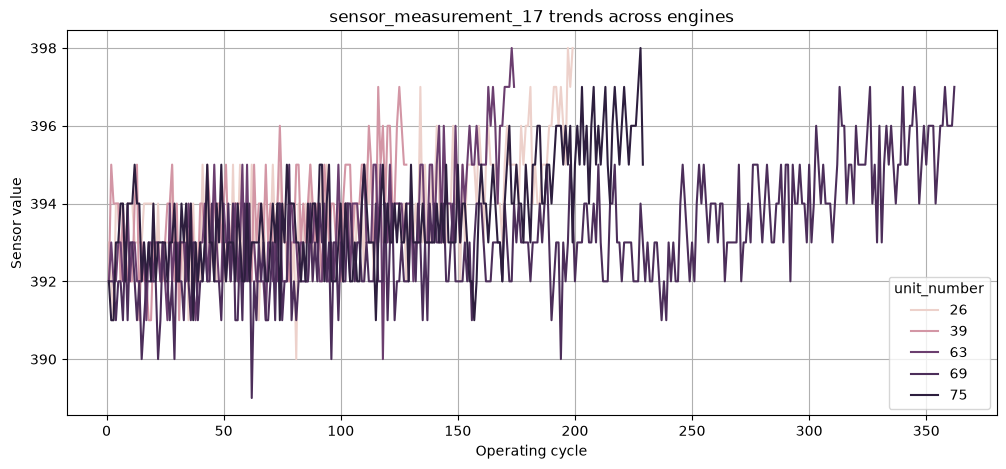

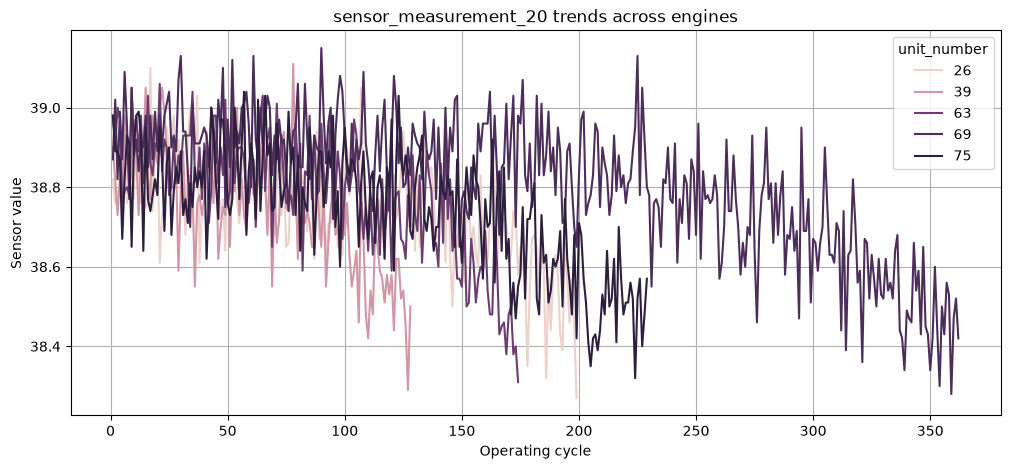

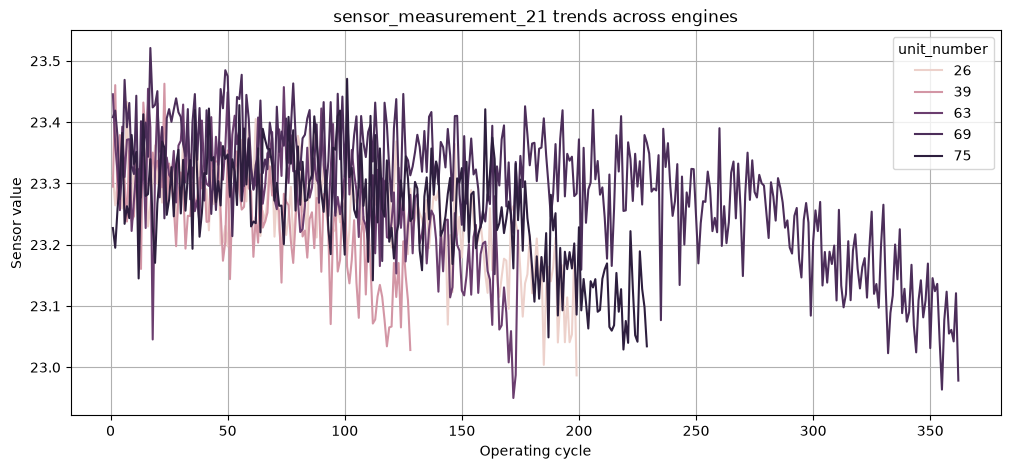

In [37]:
for column in train_columns:    
    plt.figure(figsize=(12, 5))

    sns.lineplot(
        data=train_df_minio[train_df_minio["unit_number"].isin(train_select_engines)],
        x="time_in_cycles",
        y=column,
        hue="unit_number"
    )

    plt.title(f"{column} trends across engines")
    plt.xlabel("Operating cycle")
    plt.ylabel("Sensor value")
    plt.grid(True)
    plt.show()

In [ ]:
temp = [column for column in train_columns]
temp.append("time_in_cycles")
temp.append("remaining_useful_life")

In [82]:
temp

['sensor_measurement_2',
 'sensor_measurement_3',
 'sensor_measurement_4',
 'sensor_measurement_6',
 'sensor_measurement_7',
 'sensor_measurement_8',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_13',
 'sensor_measurement_14',
 'sensor_measurement_15',
 'sensor_measurement_17',
 'sensor_measurement_20',
 'sensor_measurement_21',
 'time_in_cycles',
 'remaining_useful_life']

In [76]:
train_engine_lifetime
temp_train_df = train_df_minio.merge(train_engine_lifetime,on="unit_number",how="left")
temp_train_df = temp_train_df.rename(columns={"time_in_cycles_y":"last_cycle","time_in_cycles_x":"time_in_cycles"})

In [78]:
temp_train_df["remaining_useful_life"] = temp_train_df["last_cycle"] - temp_train_df["time_in_cycles"]

In [83]:
temp_train_df = temp_train_df.drop(columns=["last_cycle"])
temp_train_df.tail()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21,remaining_useful_life
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,2388.26,8137.60,8.4956,0.03,397.0,2388.0,100.0,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,2388.22,8136.50,8.5139,0.03,395.0,2388.0,100.0,38.30,23.1594,3
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,2388.24,8141.05,8.5646,0.03,398.0,2388.0,100.0,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,2388.23,8139.29,8.5389,0.03,395.0,2388.0,100.0,38.29,23.0640,1
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,2388.26,8137.33,8.5036,0.03,396.0,2388.0,100.0,38.37,23.0522,0


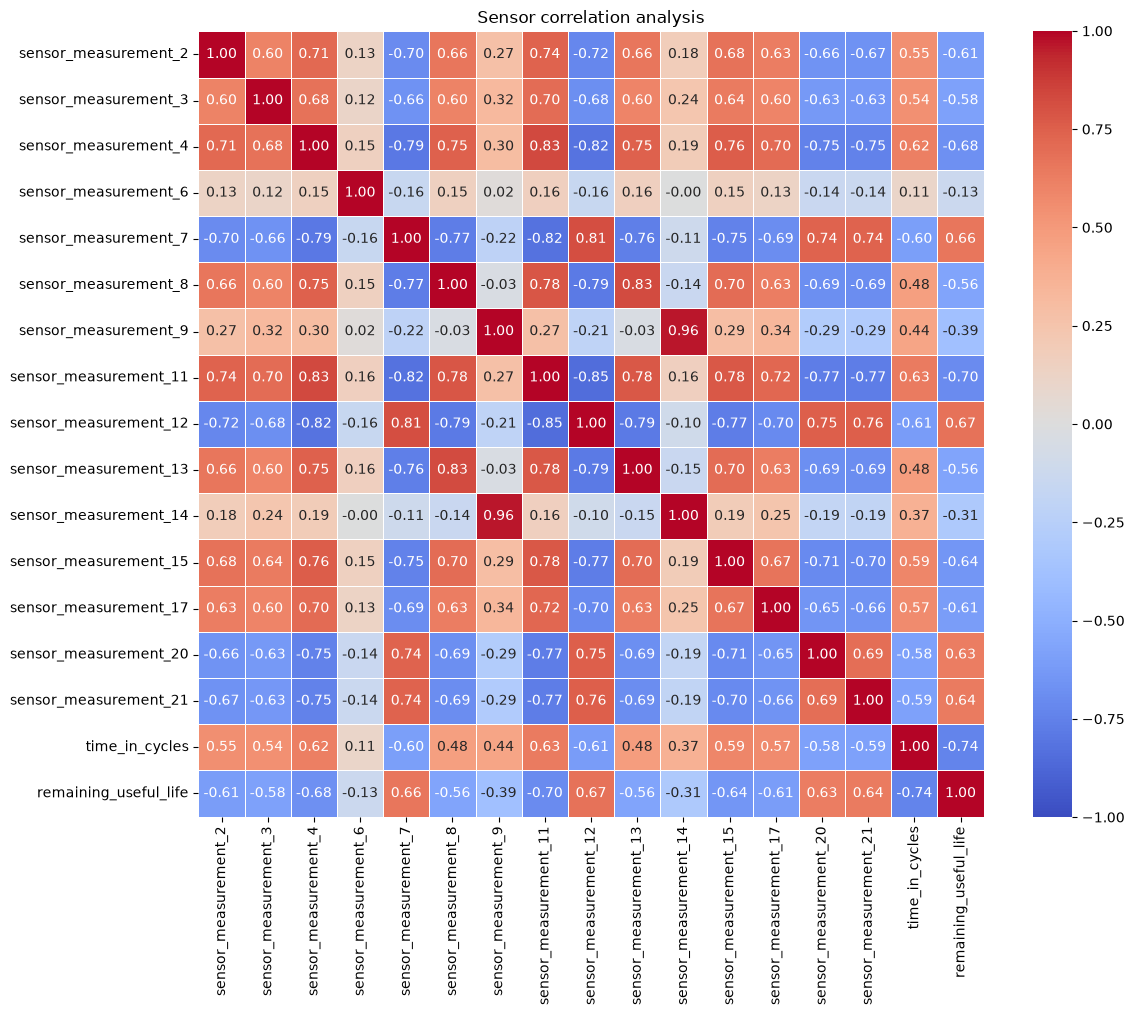

In [84]:
corr_matrix = temp_train_df[temp].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',   # diverging colormap -- shows negative vs positive distinctly
    vmin=-1, vmax=1,    # correlation's true range, not 0-1
    center=0,
    square=True,
    linewidths=0.5
)
plt.title('Sensor correlation analysis')
plt.tight_layout()
plt.show()

In [ ]:
temp = [column for column in test_columns]
temp.append("time_in_cycles")
temp.append("remaining_useful_life")

['sensor_measurement_2',
 'sensor_measurement_3',
 'sensor_measurement_4',
 'sensor_measurement_6',
 'sensor_measurement_7',
 'sensor_measurement_8',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_13',
 'sensor_measurement_14',
 'sensor_measurement_15',
 'sensor_measurement_17',
 'sensor_measurement_20',
 'sensor_measurement_21',
 'time_in_cycles']

In [113]:
temp

['sensor_measurement_2',
 'sensor_measurement_3',
 'sensor_measurement_4',
 'sensor_measurement_6',
 'sensor_measurement_7',
 'sensor_measurement_8',
 'sensor_measurement_9',
 'sensor_measurement_11',
 'sensor_measurement_12',
 'sensor_measurement_13',
 'sensor_measurement_14',
 'sensor_measurement_15',
 'sensor_measurement_17',
 'sensor_measurement_20',
 'sensor_measurement_21',
 'time_in_cycles',
 'remaining_useful_life']

In [104]:
rul_and_test_temp_df = test_df_minio.merge(rul_df_minio,on="unit_number",how="left")

In [105]:
max_test_cycle_df = rul_and_test_temp_df.groupby("unit_number").agg(max_test_cycle = ("time_in_cycles","max")).reset_index()

In [106]:
rul_and_test_df = rul_and_test_temp_df.merge(max_test_cycle_df,on="unit_number",how="left")

In [108]:
rul_and_test_df["remaining_useful_life"] = rul_and_test_df["remaining_useful_life"] + rul_and_test_df["max_test_cycle"]

In [110]:
rul_and_test_df = rul_and_test_df.drop(columns=["max_test_cycle"])
rul_and_test_df["remaining_useful_life"] = rul_and_test_df["remaining_useful_life"] - rul_and_test_df["time_in_cycles"]

In [112]:
rul_and_test_df.tail()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21,remaining_useful_life
13091,100,194,0.0049,0.0000,100.0,518.67,643.24,1599.45,1415.79,14.62,...,2388.00,8213.28,8.4715,0.03,394.0,2388.0,100.0,38.65,23.1974,24
13092,100,195,-0.0011,-0.0001,100.0,518.67,643.22,1595.69,1422.05,14.62,...,2388.09,8210.85,8.4512,0.03,395.0,2388.0,100.0,38.57,23.2771,23
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,2388.04,8217.24,8.4569,0.03,395.0,2388.0,100.0,38.62,23.2051,22
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,2388.08,8220.48,8.4711,0.03,395.0,2388.0,100.0,38.66,23.2699,21
13095,100,198,0.0013,0.0003,100.0,518.67,642.95,1601.62,1424.99,14.62,...,2388.05,8214.64,8.4903,0.03,396.0,2388.0,100.0,38.70,23.1855,20


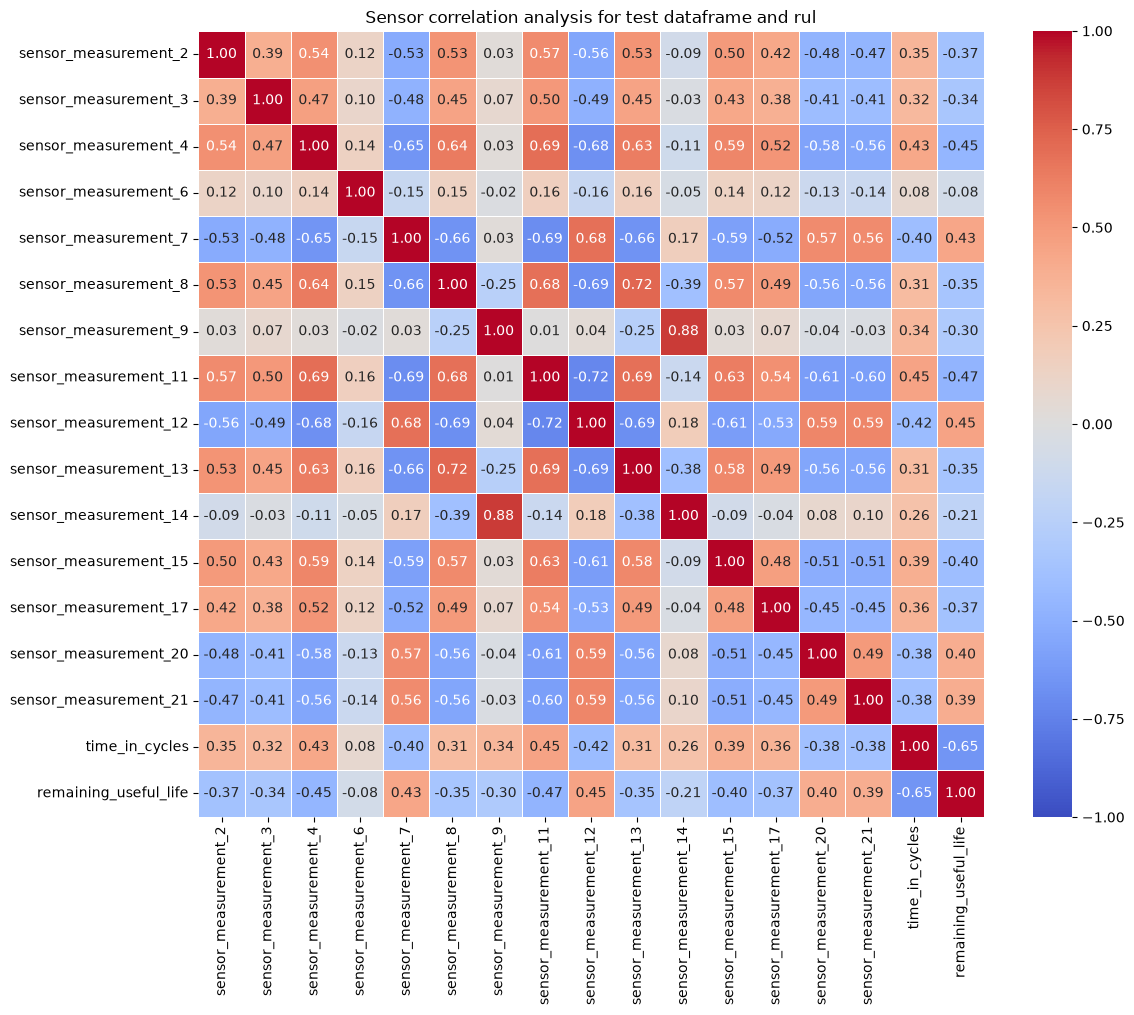

In [114]:
corr_matrix = rul_and_test_df[temp].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',   # diverging colormap -- shows negative vs positive distinctly
    vmin=-1, vmax=1,    # correlation's true range, not 0-1
    center=0,
    square=True,
    linewidths=0.5
)
plt.title('Sensor correlation analysis for test dataframe and rul')
plt.tight_layout()
plt.show()

In [ ]:
train_engine_lifetime

,unit_number,time_in_cycles
0,1,192
1,2,287
2,3,179
3,4,189
4,5,269
...,...,...
95,96,336
96,97,202
97,98,156
98,99,185


In [46]:
temp = train_df_minio.merge(train_engine_lifetime,on="unit_number",how="left")
temp = temp.rename(columns={"time_in_cycles_y":"last_cycle","time_in_cycles_x":"time_in_cycles"})
temp.head()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21,last_cycle
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.4190,192
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.00,23.4236,192
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442,192
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739,192
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393.0,2388.0,100.0,38.90,23.4044,192


In [47]:
train_data_in_beginning_and_near_failure = temp[(temp["time_in_cycles"]>temp["last_cycle"]-20) | (temp["time_in_cycles"]<temp["time_in_cycles"].min()+20)]

In [48]:
train_data_in_beginning_and_near_failure = train_data_in_beginning_and_near_failure.drop(columns=["last_cycle"])

In [49]:
train_data_in_beginning_and_near_failure.head()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393.0,2388.0,100.0,38.90,23.4044


In [50]:
train_select_engines = [train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[5],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((0.25*len(train_engine_lifetime))+4)],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((0.5*len(train_engine_lifetime))+1)],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((0.75*len(train_engine_lifetime))-5)],
                        train_engine_lifetime.sort_values("time_in_cycles")["unit_number"].iloc[int((1*len(train_engine_lifetime))-6)]]

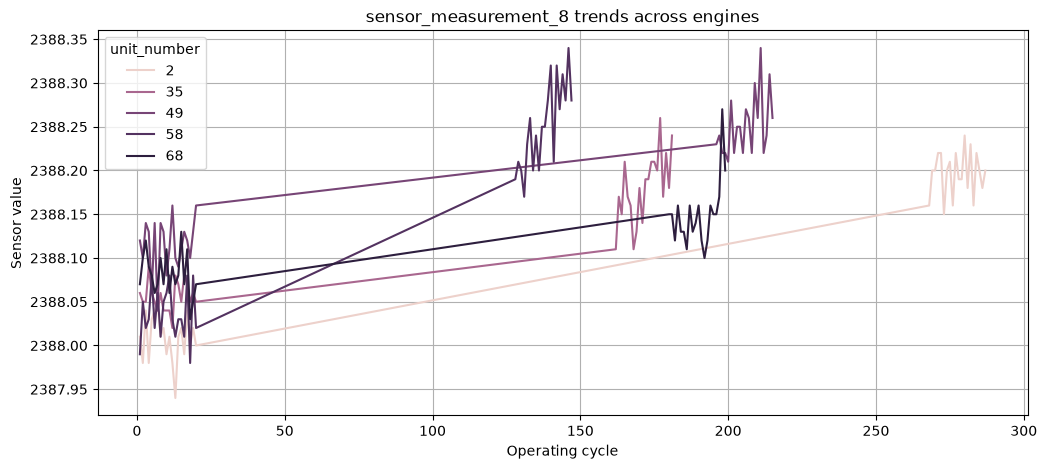

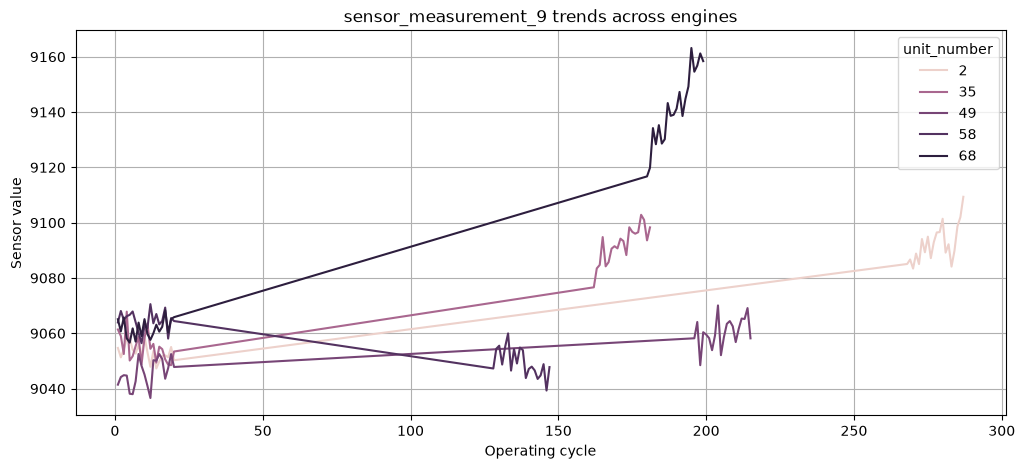

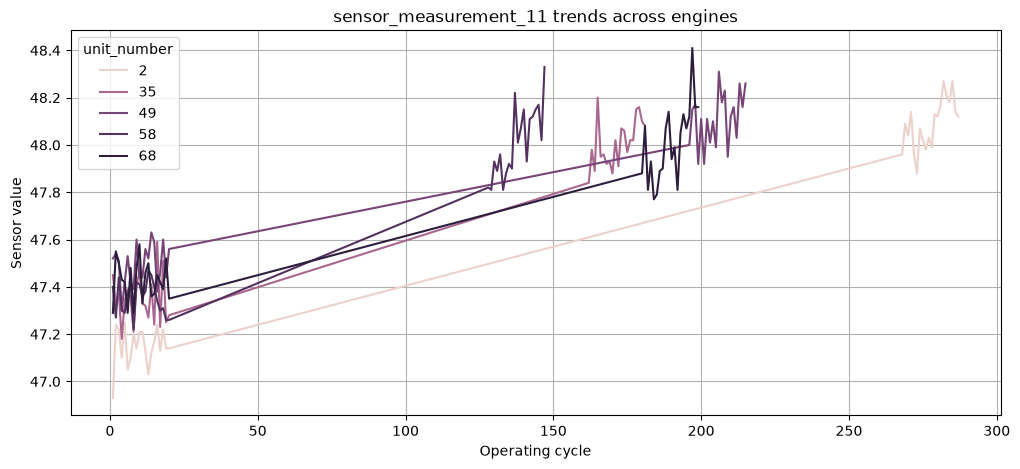

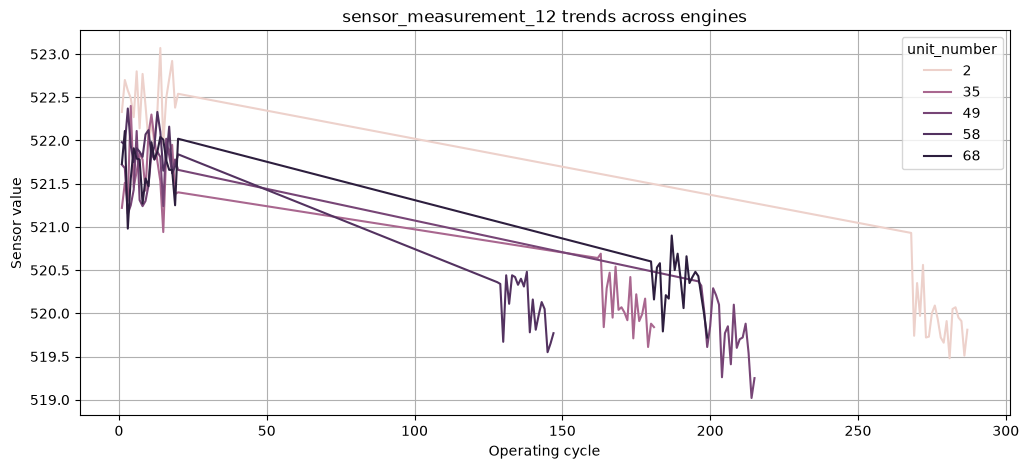

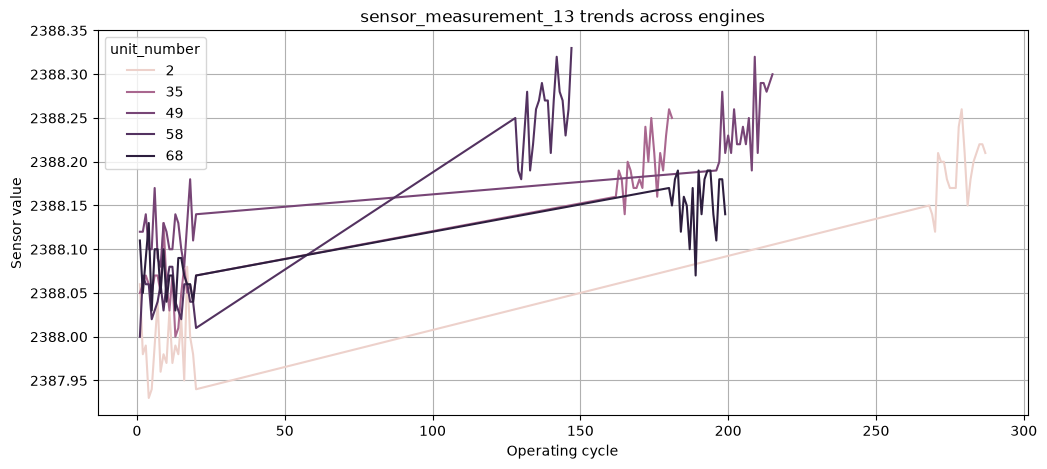

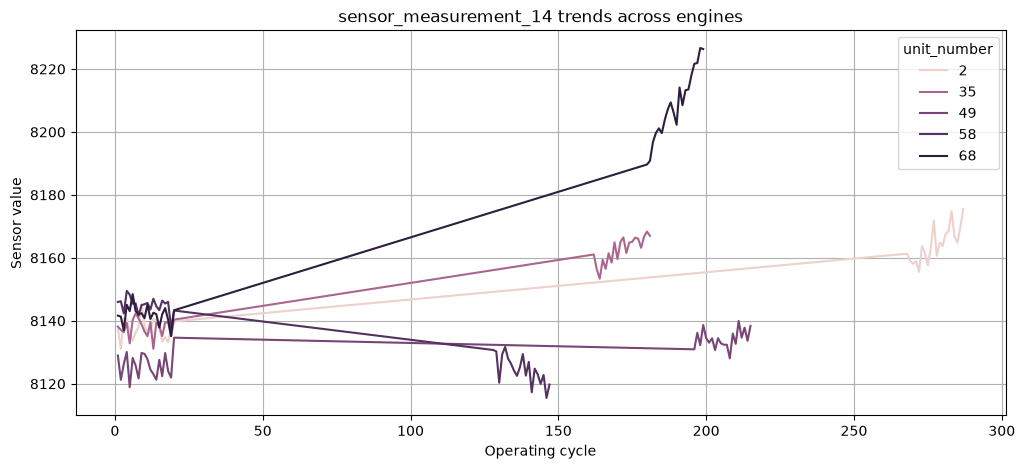

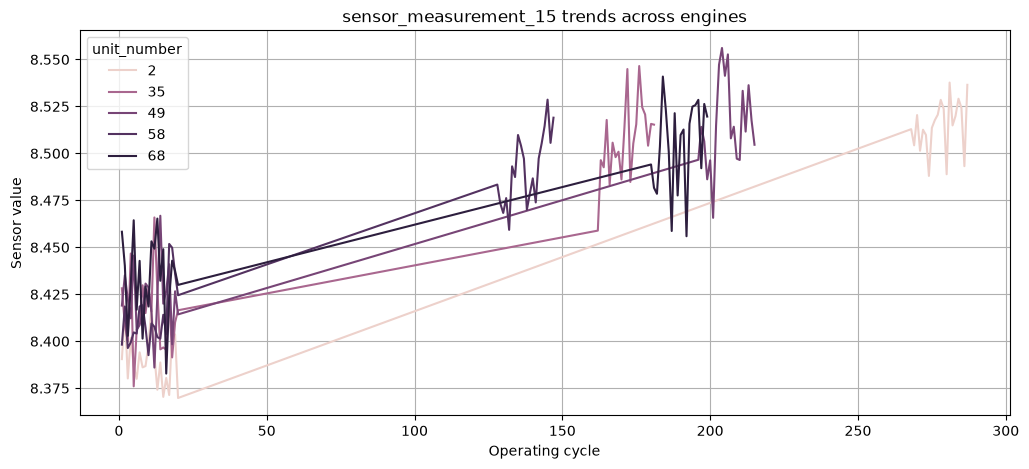

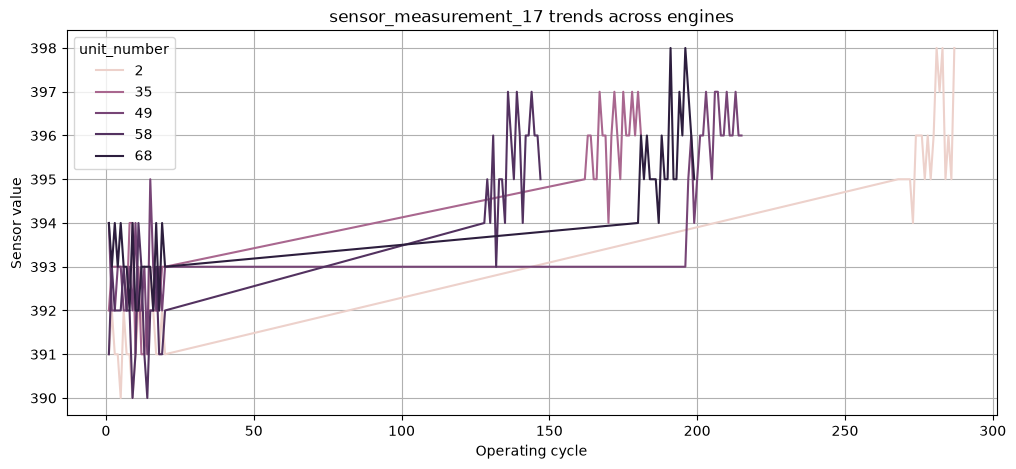

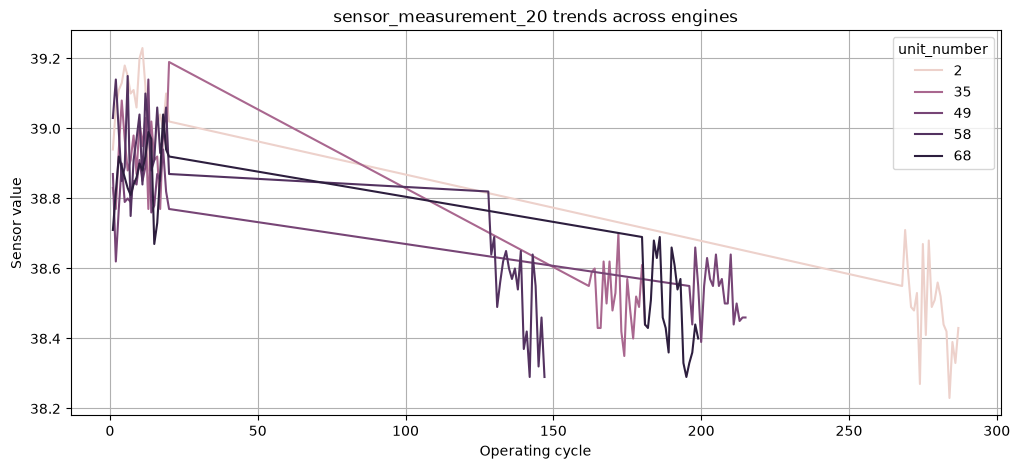

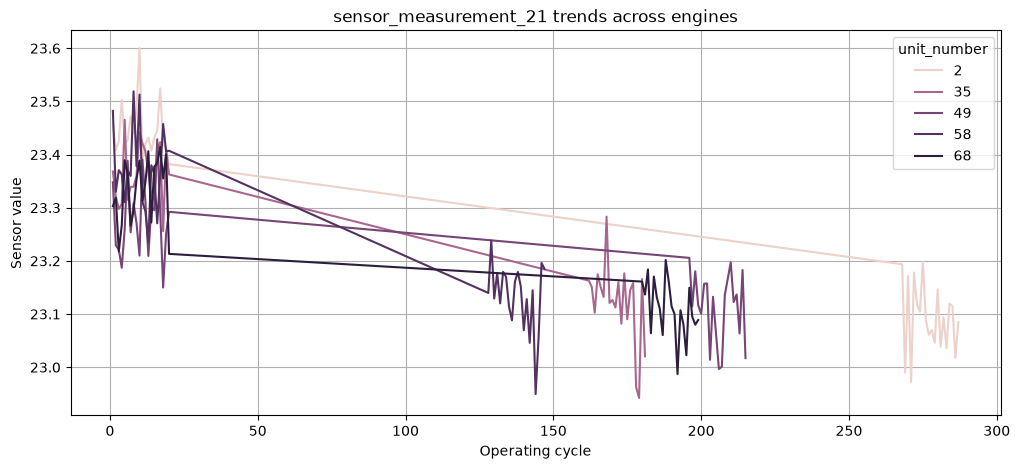

In [51]:
for column in train_columns:    
    plt.figure(figsize=(12, 5))

    sns.lineplot(
        data=train_data_in_beginning_and_near_failure[train_data_in_beginning_and_near_failure["unit_number"].isin(train_select_engines)],
        x="time_in_cycles",
        y=column,
        hue="unit_number"
    )

    plt.title(f"{column} trends across engines")
    plt.xlabel("Operating cycle")
    plt.ylabel("Sensor value")
    plt.grid(True)
    plt.show()

In [52]:
temp.head()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21,last_cycle
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.4190,192
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392.0,2388.0,100.0,39.00,23.4236,192
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390.0,2388.0,100.0,38.95,23.3442,192
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392.0,2388.0,100.0,38.88,23.3739,192
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393.0,2388.0,100.0,38.90,23.4044,192


In [53]:
train_data_in_beginning = temp[(temp["time_in_cycles"]<temp["time_in_cycles"].min()+20)]
train_data_in_beginning = train_data_in_beginning.drop(columns=["last_cycle"])

In [54]:
train_data_near_failure = temp[(temp["time_in_cycles"]>temp["last_cycle"]-20)]
train_data_near_failure = train_data_near_failure.drop(columns=["last_cycle"])

In [55]:
train_data_near_failure.head()

,unit_number,time_in_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_measurement_1,sensor_measurement_2,sensor_measurement_3,sensor_measurement_4,sensor_measurement_5,...,sensor_measurement_12,sensor_measurement_13,sensor_measurement_14,sensor_measurement_15,sensor_measurement_16,sensor_measurement_17,sensor_measurement_18,sensor_measurement_19,sensor_measurement_20,sensor_measurement_21
172,1,173,-0.0032,0.0002,100.0,518.67,642.97,1590.69,1425.27,14.62,...,520.11,2388.23,8121.64,8.5091,0.03,395.0,2388.0,100.0,38.59,23.1789
173,1,174,-0.0001,-0.0002,100.0,518.67,642.64,1599.81,1422.58,14.62,...,520.22,2388.21,8119.17,8.4476,0.03,393.0,2388.0,100.0,38.57,23.0357
174,1,175,0.0001,0.0002,100.0,518.67,643.61,1603.29,1422.52,14.62,...,520.38,2388.22,8125.76,8.4890,0.03,394.0,2388.0,100.0,38.58,23.1573
175,1,176,-0.0020,-0.0003,100.0,518.67,642.86,1592.27,1422.73,14.62,...,519.80,2388.20,8123.80,8.4853,0.03,394.0,2388.0,100.0,38.72,23.2491
176,1,177,-0.0038,-0.0003,100.0,518.67,643.79,1602.02,1423.99,14.62,...,520.24,2388.23,8120.11,8.4779,0.03,396.0,2388.0,100.0,38.63,23.1673


In [56]:
train_data_near_failure["sensor_measurement_2"].mean()

np.float64(643.48446)

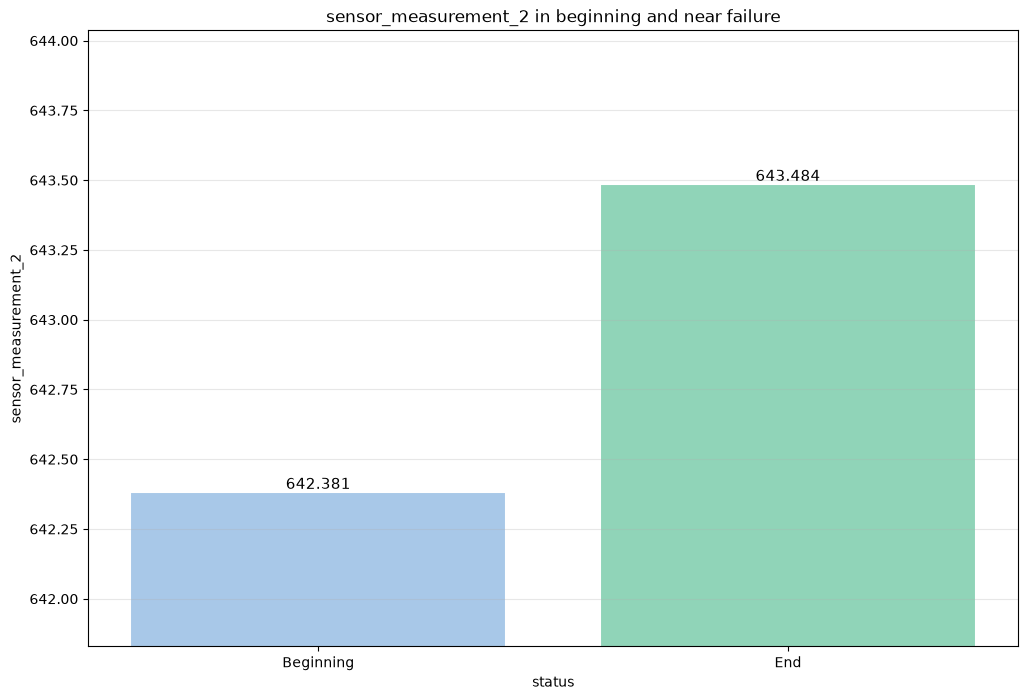

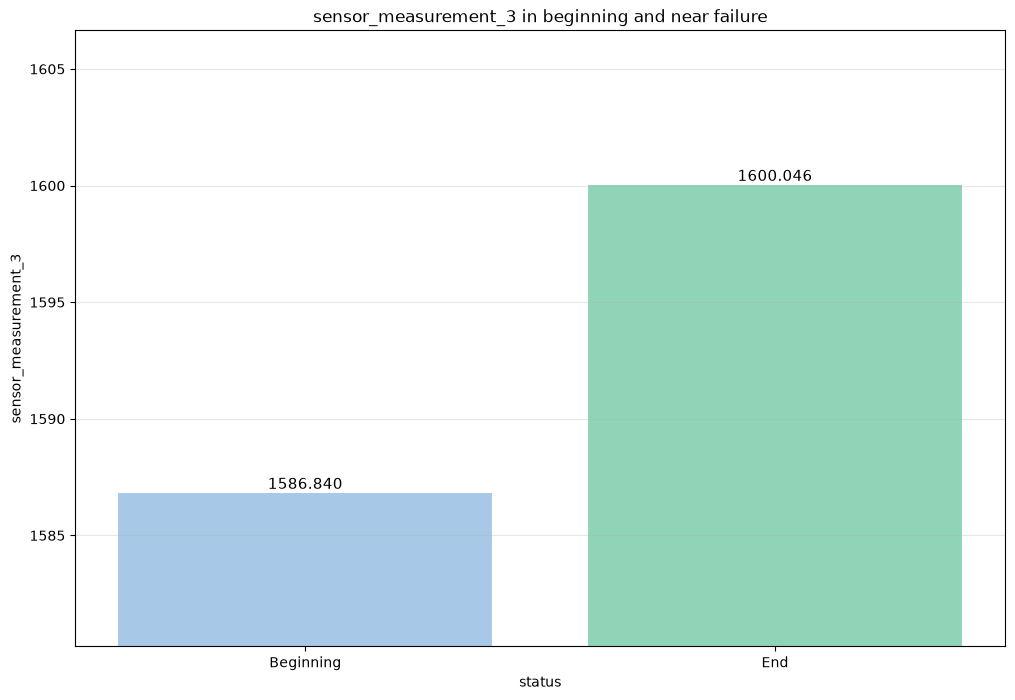

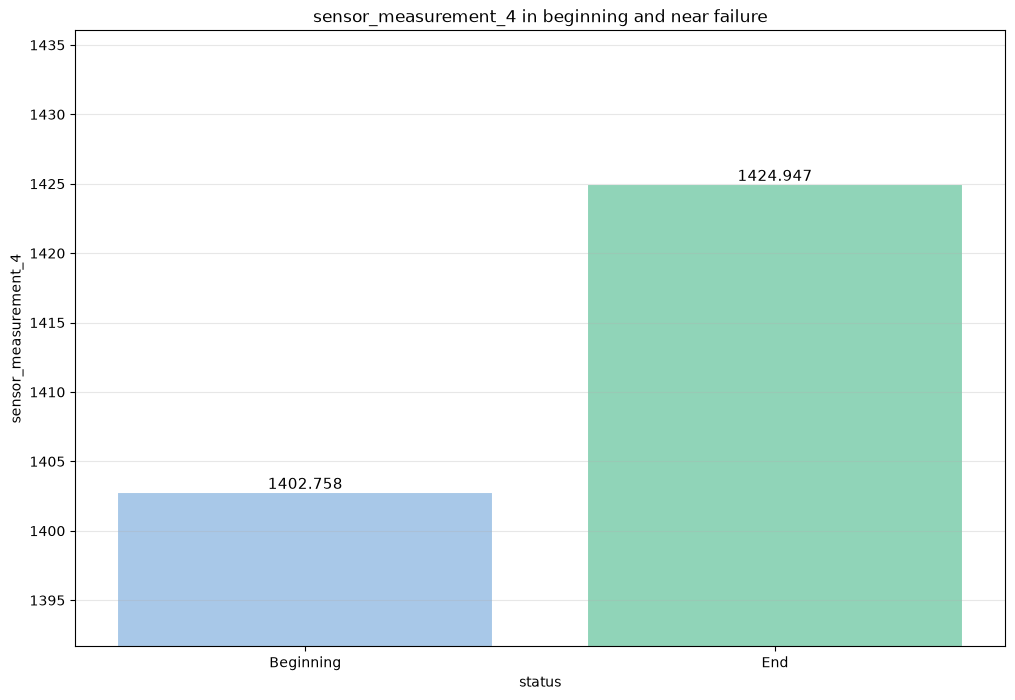

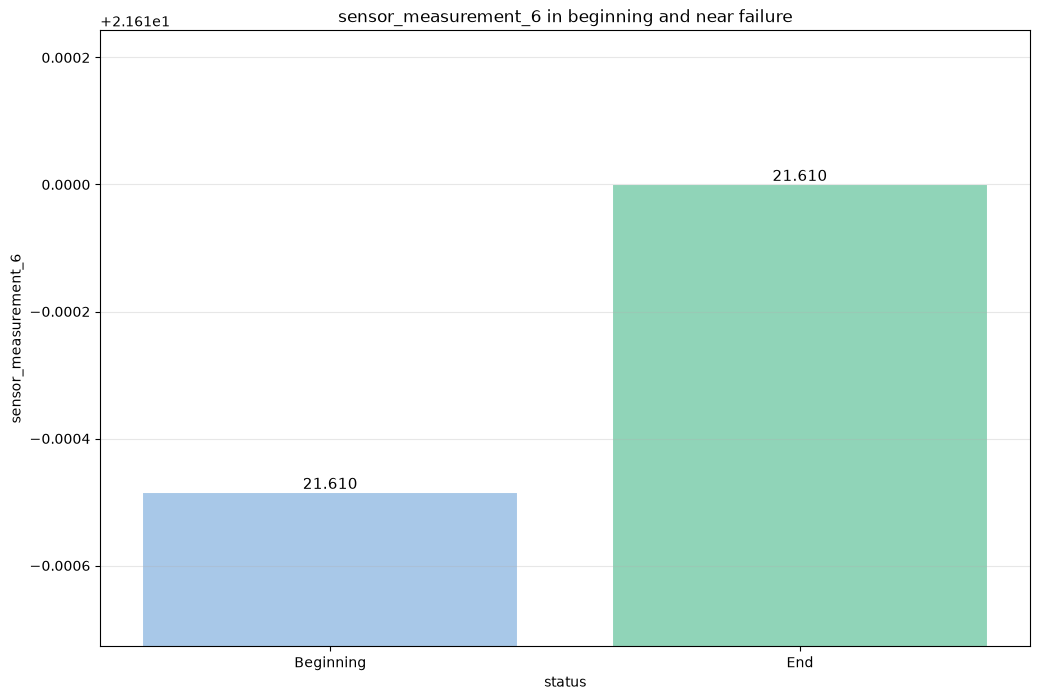

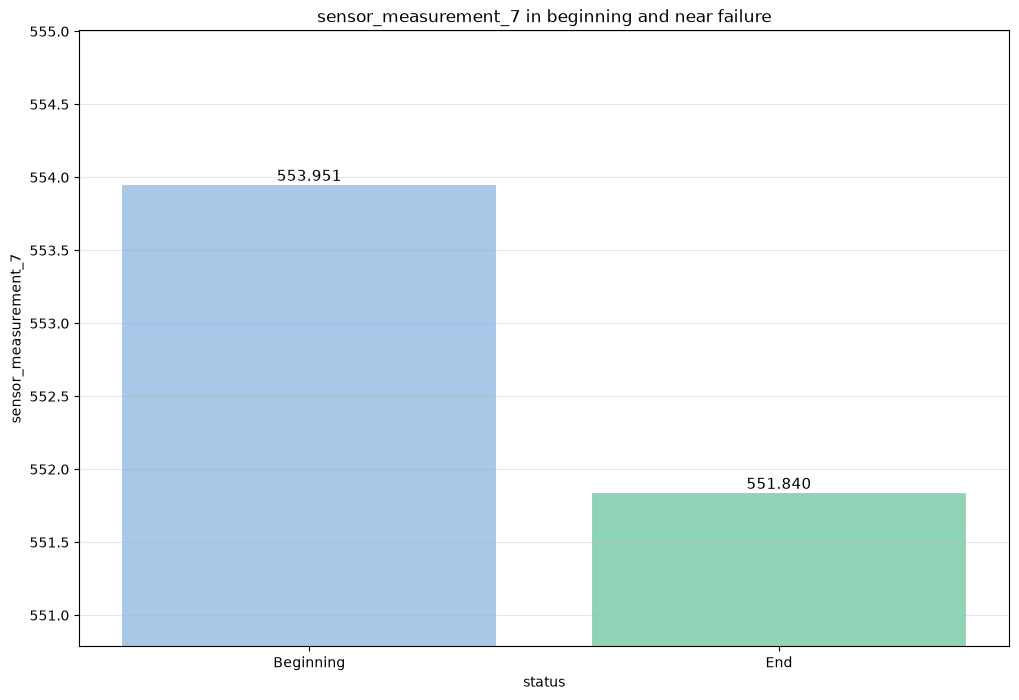

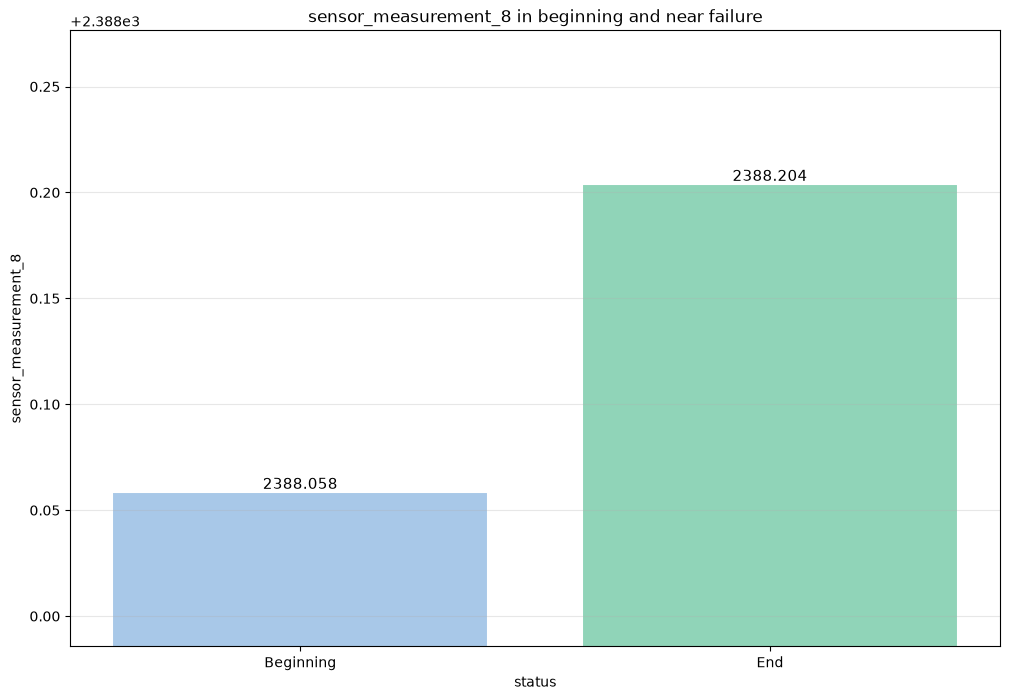

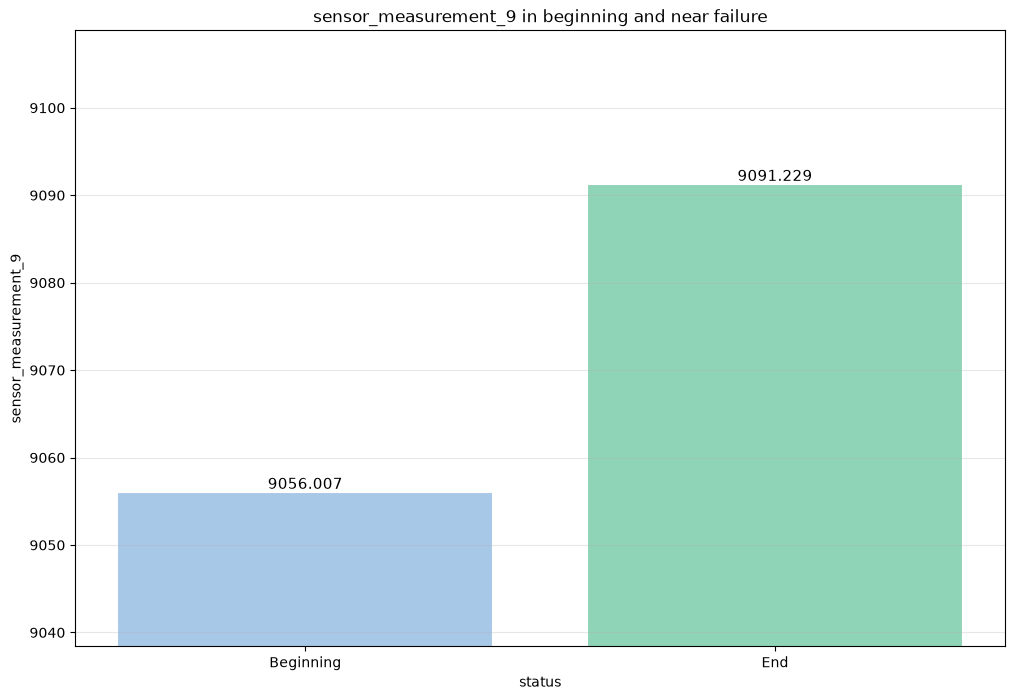

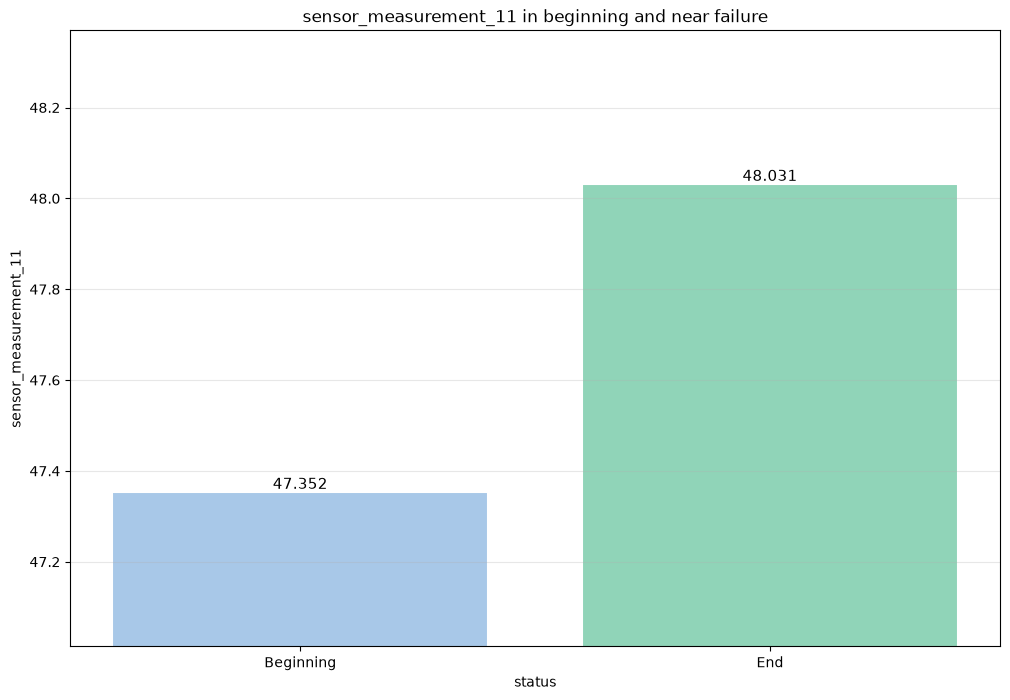

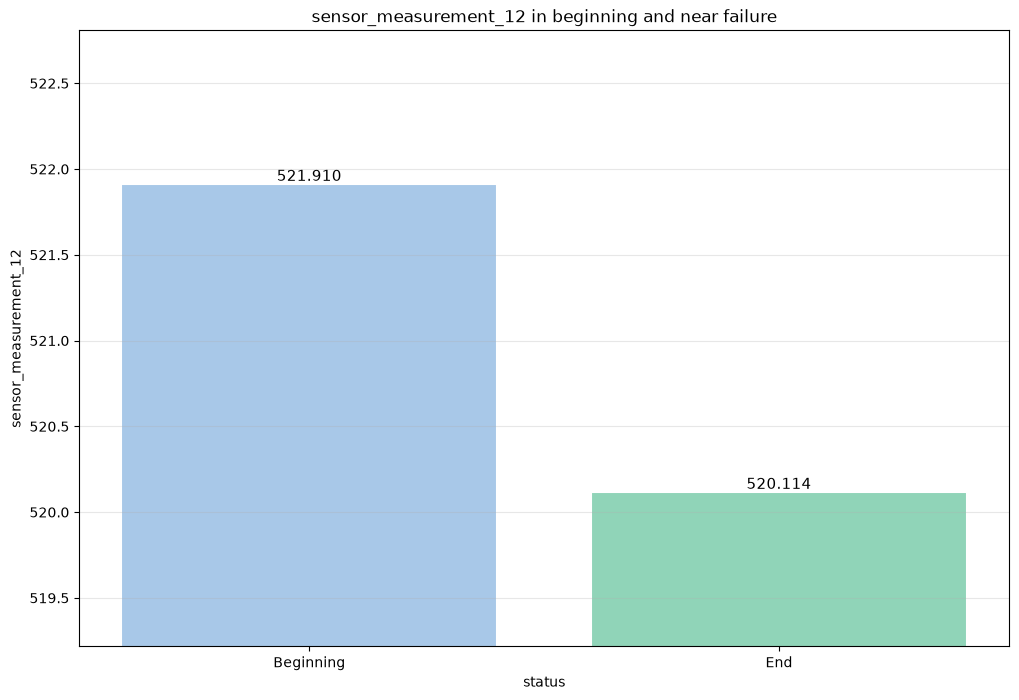

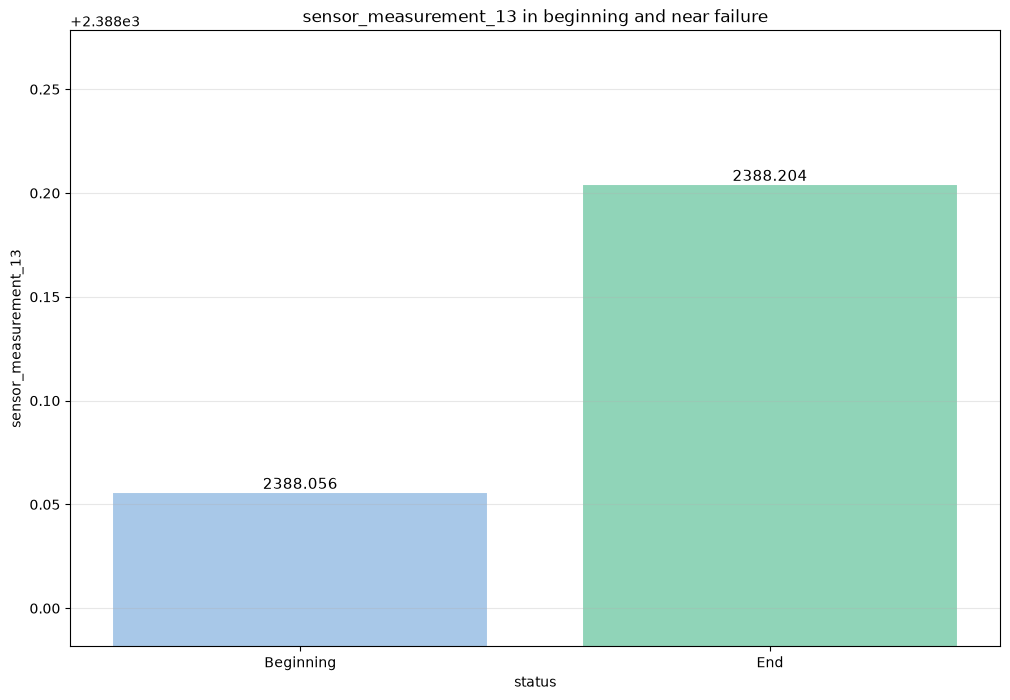

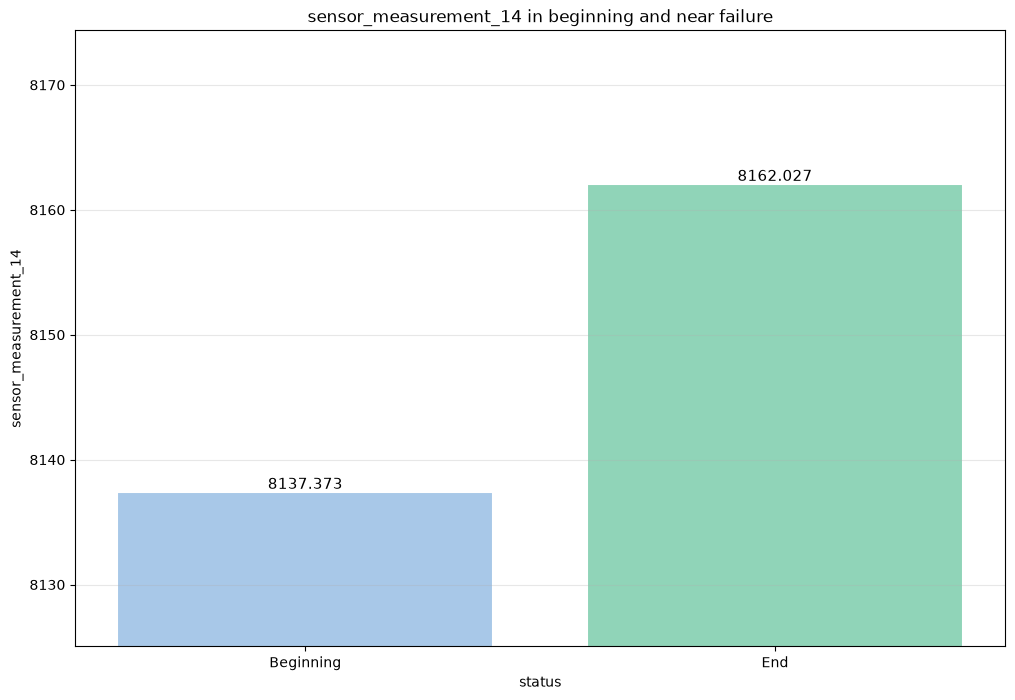

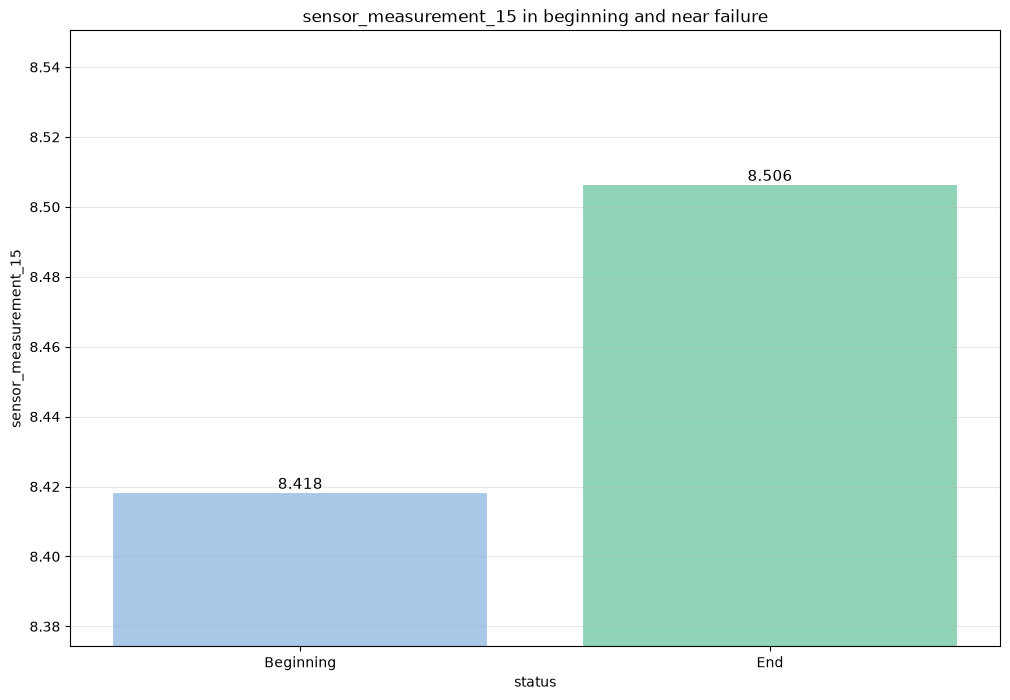

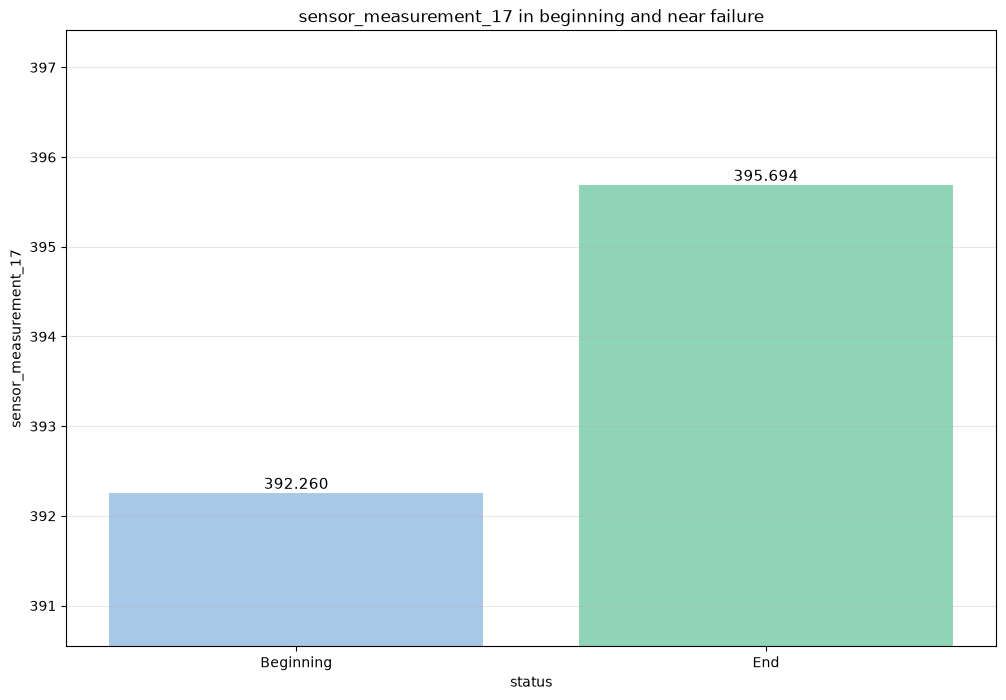

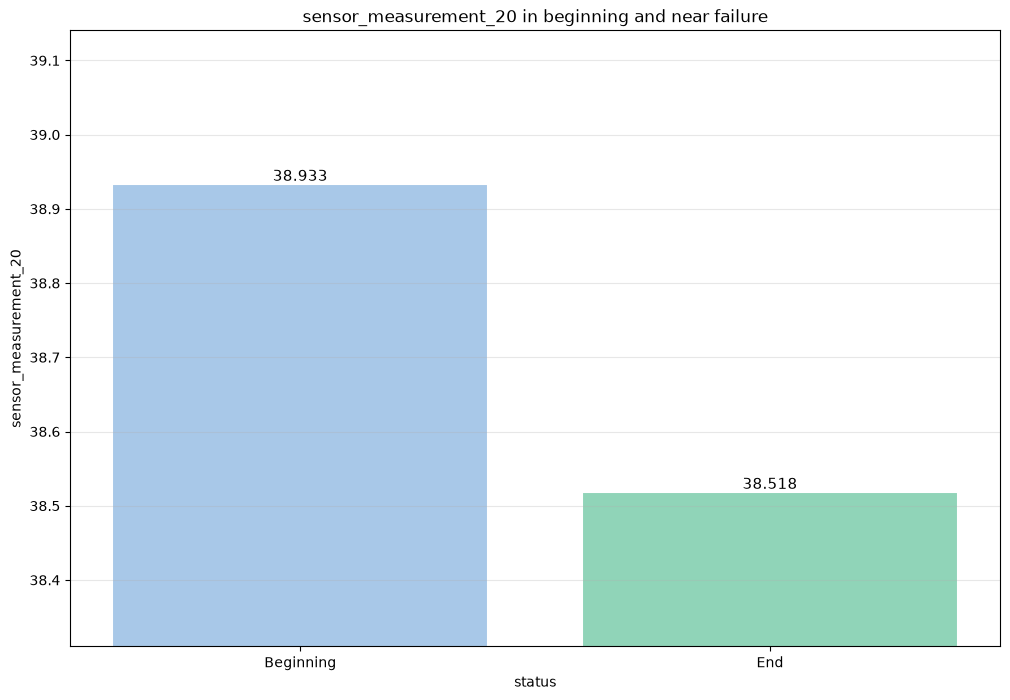

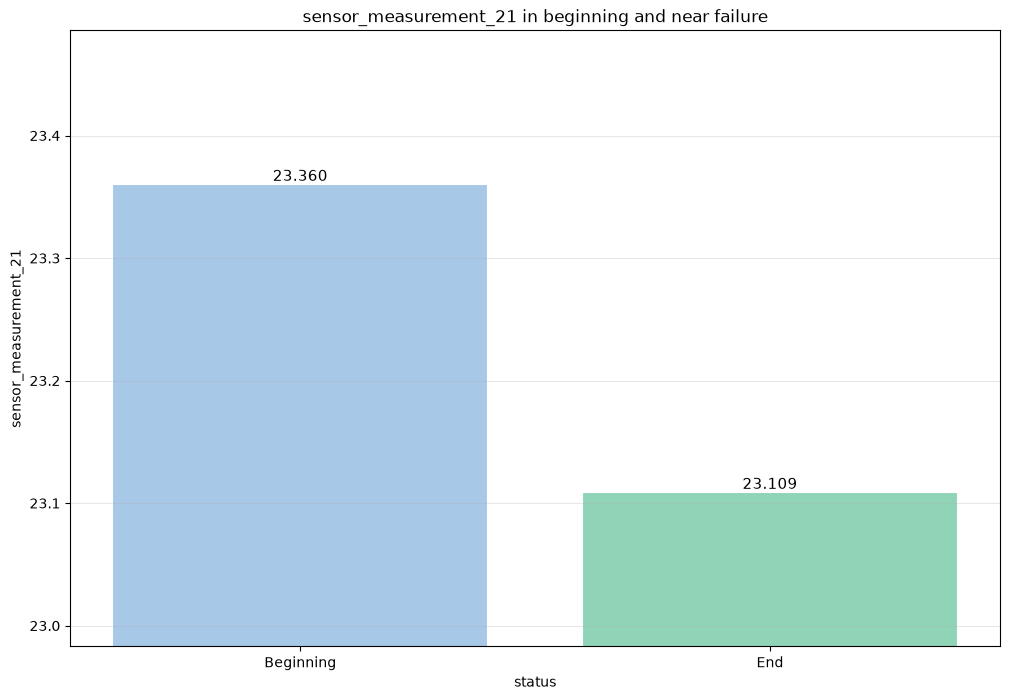

In [57]:
for column in train_columns:
    plt.figure(figsize=(12,8))
    beginning_mean = train_data_in_beginning[column].mean()
    end_mean = train_data_near_failure[column].mean()

    bars = plt.bar(
        ["Beginning","End"],
        [beginning_mean, end_mean],
        color=colors,
        edgecolor='white',
        linewidth=1.5
    )

    # Add exact value labels on top of each bar
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{height:.3f}",
            ha='center',
            va='bottom',
            fontsize=11
        )

    # Zoom the y-axis into the relevant range instead of starting at 0
    min_val = min(beginning_mean, end_mean)
    max_val = max(beginning_mean, end_mean)
    padding = (max_val - min_val) * 0.5 if max_val != min_val else max_val * 0.1
    plt.ylim(min_val - padding, max_val + padding)

    plt.title(f"{column} in beginning and near failure")
    plt.xlabel("status")
    plt.ylabel(column)
    plt.grid(True, axis='y', alpha=0.3)
    plt.show()

# Phase 3 conclusions

## Sensor behavior over engine lifetime

The exploratory analysis shows that several sensors exhibit clear temporal changes across the engine trajectories. `sensor_measurement_2`, `sensor_measurement_3`, `sensor_measurement_4`, `sensor_measurement_8`, `sensor_measurement_11`, `sensor_measurement_13`, `sensor_measurement_15`, and `sensor_measurement_17` generally increase as the engines progress through their operating cycles. In contrast, `sensor_measurement_7`, `sensor_measurement_12`, `sensor_measurement_20`, and `sensor_measurement_21` generally decrease. `sensor_measurement_9` and `sensor_measurement_14` show more heterogeneous behavior: their values increase for some engines while remaining relatively stable for others. These observations suggest that degradation patterns are not identical across all engines.

## Stable variables and train-test behavior

The variables identified in `train_constant_columns` and `test_constant_columns` are constant in the corresponding FD001 datasets. Since they contain no meaningful variation, they are unlikely to help distinguish engine states in an initial model. The training and test datasets show broadly similar sensor distributions for the variables examined. However, the test trajectories are deliberately truncated before failure, so the test data contain less representation of late-stage degradation than the complete training trajectories. Similar overall ranges should therefore not be interpreted as identical lifecycle coverage.

## Early-life and near-failure behavior

The comparison between early-life observations and observations near the end of the training trajectories indicates that most non-constant sensors differ in their distributions or average values. This supports the idea that sensor measurements contain information about degradation. These are population-level comparisons and do not prove that every engine follows exactly the same pattern. The different behavior of `sensor_measurement_9` and `sensor_measurement_14` is particularly important because it demonstrates engine-to-engine variation.

The possibility that some engines begin with different levels of initial degradation may help explain these differences. The C-MAPSS documentation describes initial wear and manufacturing variation between engines. Nevertheless, the current analysis does not prove that an engine was previously used or that lifetime can be determined from the stability of only a few sensors. This remains a hypothesis for further investigation.

## RUL distribution and sensor-to-RUL relationship

The RUL distribution plot describes the terminal `remaining_useful_life` values supplied for the 100 test engines. Each supplied value represents the RUL at that engine's final observed test cycle.

For the sensor-to-RUL analysis, the terminal RUL is converted into a per-cycle RUL value. For each engine, the estimated failure cycle is calculated as `max_test_cycle + supplied_terminal_RUL`, and the RUL at each observed cycle is then calculated as `estimated_failure_cycle - current_cycle`. For example, if an engine's final test cycle is 50 and its supplied RUL is 10, its estimated failure cycle is 60; its RUL is therefore 20 at cycle 40 and 10 at cycle 50.

The resulting heatmap therefore represents a per-cycle sensor-to-RUL relationship for the test trajectories. Because these RUL values are derived from the test labels, this analysis is descriptive only. Final feature-selection and model-development decisions should use the per-cycle `remaining_useful_life` target from the Gold training features dataset, without using test labels.

## Interpreting apparent outliers

The IQR analysis identifies statistical observations requiring investigation, not automatically invalid records. An unusual sensor value may be a genuine degradation signal when it appears repeatedly, changes gradually, or occurs near the end of an engine trajectory. An isolated spike that quickly returns to its previous level is more likely to represent measurement noise. The outlier analysis will therefore guide investigation rather than justify automatic row removal.


## Feature availability decision

All original columns remain available in `train_df_minio` and `test_df_minio`. The `train_columns` and `test_columns` lists are temporary selections used for particular EDA visualizations and correlation analyses; they do not delete columns from the original DataFrames. Operational settings, engine identifiers, time, and constant variables are therefore still preserved. During Phase 4, derived variables such as rolling averages, slopes, changes, and volatility measures will be added as new columns while the original variables are retained.

The constant variables appear non-informative for FD001 because they do not vary, but this is an FD001-specific observation rather than a universal rule for every C-MAPSS subset. Operational settings have not yet been classified as useless because their relationship with the sensor measurements still needs to be investigated.

## Operating-condition scope

FD001 represents one main operating condition and one principal degradation mode. Therefore, this notebook does not compare multiple operating regimes. The operational-setting columns remain preserved in the data, and their relationship with the sensor measurements can be investigated during Phase 4.

## Guidance for Phase 4 — feature engineering

Phase 4 should investigate the operational settings and their relationship with the sensor measurements, especially whether they help distinguish operating-condition effects from degradation effects. `sensor_measurement_9` and `sensor_measurement_14` should receive particular attention because their trajectories vary between engines. All non-constant sensors should remain candidates for feature engineering through rolling averages, slopes, recent changes, volatility, and deviations from each engine's earlier behavior.

Feature investigation should account for engine-to-engine differences rather than relying only on global correlation. No final feature-removal decision is made in Phase 3; those decisions will be evaluated later using leakage-safe feature engineering and baseline model performance.

### Phase 3 outcome

The main conclusion is that FD001 contains useful degradation information, but the sensor trajectories are noisy and differ across engines. RUL prediction will therefore require time-series features that capture both recent sensor behavior and the individual history of each engine.